# Laboratório 7: Sarsa (CliffWalking)

## Importações

In [ ]:
!pip install gymnasium[toy-text]                                                # CliffWalking e FrozenLake (inclui o pygame)
!pip install tqdm pandas seaborn                                                # Barra de progresso, tabelas e gráficos
!pip install gdown                                                              # Download do rl_utils.py e das figuras

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 18.0 MB/s  0:00:00


In [ ]:
import os                                                                       # Verificação de arquivos
import gdown                                                                    # Download de arquivos do Google Drive
from IPython.display import SVG, display                                        # Exibição das figuras (SVG)
import gymnasium as gym                                                         # Ambientes de aprendizado por reforço
from gymnasium.wrappers import RecordEpisodeStatistics                          # Estatísticas por episódio
import numpy as np                                                              # Operações numéricas e vetoriais
import pandas as pd                                                             # Tabelas de resultados
import matplotlib.pyplot as plt                                                 # Gráficos
from tqdm.auto import tqdm                                                      # Barra de progresso
from typing import NamedTuple, Optional, List, Tuple                            # Anotações de tipo e tuplas nomeadas
from collections import deque                                                   # Fila com tamanho máximo

## Funções auxiliares para visualização

In [ ]:
RL_UTILS_URL = "https://drive.google.com/file/d/1AEJC-YWgeZCr8pZEOOiAg6PNK8IrBBRk/view?usp=sharing"

if not os.path.exists("rl_utils.py"):                                           # Baixa o módulo só se ainda não existir
    try:
        gdown.download(RL_UTILS_URL, "rl_utils.py", quiet=True, fuzzy=True)
    except Exception as error:
        print(f"Falha no download: {error}")

from rl_utils import (                                                          # Funções comuns aos labs da Unidade 2
    plot_results, plot_comparison,                                              # Curvas de treinamento
    simulate_trajectory, plot_trajectory,                                       # Trajetória sobre a grade
    show_one_episode,                                                           # Animação de um episódio
    plot_tabular, plot_policy_distributions,                                    # Heatmaps de q, pi e v; distribuições pi(.|s)
)

In [ ]:
FIGURE_URLS = {                                                                 # Links das figuras (SVG) no Google Drive
    "mapa_cliffwalking":
        "https://drive.google.com/file/d/1x1Poz-iZ3IcW-aLyYCwDMN7DPHlo5_So/view?usp=sharing",
    "env_step":
        "https://drive.google.com/file/d/1csEbTeLIz7a8-FDz0xwrd_M_T-_Z0Dj5/view?usp=sharing",
    "epsilon_gulosa":
        "https://drive.google.com/file/d/1LtJYLSN-zlitE6BMPHNTVoIuZcGcOymD/view?usp=sharing",
    "sarsa_passo":
        "https://drive.google.com/file/d/18WQjx3G9-XmY37-tdIr79BQJmvDKJJVG/view?usp=sharing",
}
FIGURE_DIR = "figuras"                                                          # Pasta local das figuras

os.makedirs(FIGURE_DIR, exist_ok=True)
for name, url in FIGURE_URLS.items():
    path = os.path.join(FIGURE_DIR, f"{name}.svg")
    if not os.path.exists(path):                                                # Baixa só se ainda não existir
        try:
            gdown.download(url, path, quiet=True, fuzzy=True)
        except Exception as error:
            print(f"Falha no download de {name}: {error}")


def show_figure(name: str) -> None:
    path = os.path.join(FIGURE_DIR, f"{name}.svg")
    try:
        display(SVG(filename=path))                                             # A figura aparece como saída da célula
    except Exception:                                                           # Arquivo ausente ou inválido
        print(f"Figura indisponível: {name}. Confira o link em FIGURE_URLS.")

## Ambiente: nova instância

O laboratório usa o `CliffWalking-v1`, do [Gymnasium](https://gymnasium.farama.org/environments/toy_text/cliff_walking/).

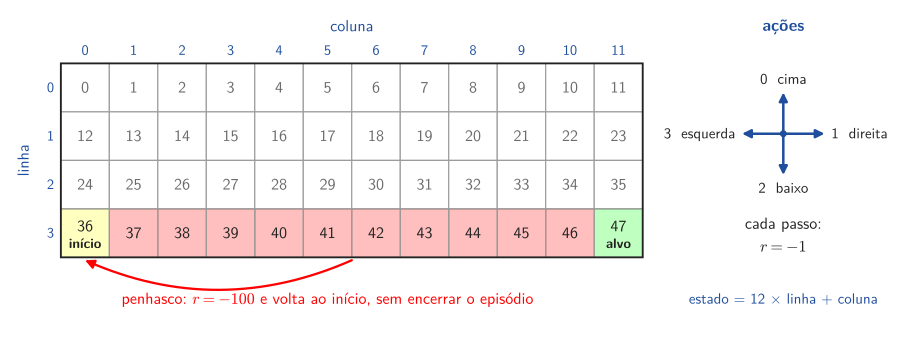

In [ ]:
show_figure("mapa_cliffwalking")                                                # Mapa do CliffWalking

- **Estado:** o índice da célula, `12 * linha + coluna`, que é também a observação devolvida pelo ambiente.
- **Ações:** quatro; não há a ação de permanecer no lugar.
- **Recompensa:** $-1$ por passo. Quanto mais curto o caminho, maior a recompensa total, e o caminho mais curto passa rente ao penhasco.
- **Penhasco:** entrar nele custa $-100$ e devolve o agente a $s_0 = 36$, **sem** encerrar o episódio.
- **Fim do episódio:** há um estado terminal, o alvo. Como um agente que ainda não aprendeu pode vagar por muito tempo, o episódio também termina ao atingir um limite de passos.
- **Modelo:** não é usado. O agente aprende só com as amostras de experiência devolvidas por `env.step`, e não com um modelo como o `env.P` do FrozenLake (Laboratório 3).

A célula abaixo define as constantes e `make_env`, que cria o ambiente com o limite de passos e o envolve com o wrapper `RecordEpisodeStatistics`. Cada treinamento deve usar um ambiente novo, criado por `make_env`.

<details>
<summary><b>Detalhes:</b> <code>RecordEpisodeStatistics</code> </summary>

- No último passo de cada episódio, acrescenta a `info` a entrada `info["episode"]`, com:
  - `"r"`: a recompensa total, isto é, a soma das recompensas, sem desconto;
  - `"l"`: a duração, em passos;
  - `"t"`: o tempo de execução, em segundos.
- Guarda esses valores dos últimos `STATS_BUFFER_LENGTH` episódios nas filas `return_queue`, `length_queue` e `time_queue`, usadas nas médias da barra de progresso.
- Um ambiente novo começa com as filas vazias.

</details>

In [ ]:
ENV_ID = "CliffWalking-v1"                                                      # Identificador do ambiente
MAX_EPISODE_STEPS = 500                                                         # Limite de passos por episódio
STATS_BUFFER_LENGTH = 100                                                       # Tamanho das filas e janela das médias
SEED = 42                                                                       # Semente para reprodutibilidade


def make_env(render_mode: Optional[str] = "rgb_array") -> gym.Env:
    env = gym.make(ENV_ID, render_mode=render_mode,                             # "rgb_array": render() devolve imagem
                   max_episode_steps=MAX_EPISODE_STEPS)                         # truncated = True no limite
    return RecordEpisodeStatistics(env, buffer_length=STATS_BUFFER_LENGTH)      # Registra r, l e t dos episódios


env = make_env()                                                                # Instância para inspeção

`env.reset` inicia um episódio e devolve o estado inicial $s_0$ e o dicionário `info`.

In [ ]:
obs, info = env.reset(seed=SEED)                                                # Estado inicial s_0
obs, info

(36, {'prob': 1})

`env.render()` devolve a imagem do estado atual, um array com shape `(altura, largura, 3)`.

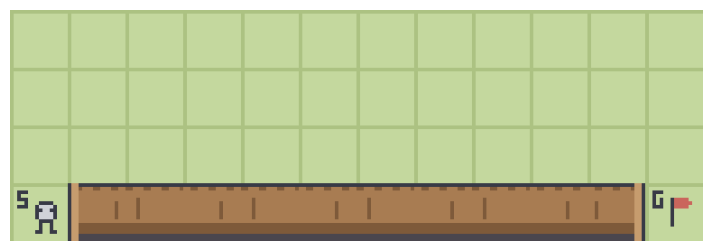

(256, 768, 3)

In [ ]:
img = env.render()                                                              # Imagem RGB do estado atual
plt.figure(figsize=(9, 3))
plt.imshow(img)
plt.axis("off")
plt.show()
img.shape                                                                       # (altura, largura, canais)

`env.step` executa um passo. Ele recebe só a ação $a_t$, porque o ambiente já guarda o estado atual $s_t$:

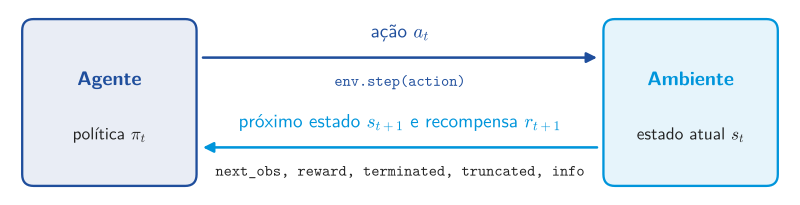

In [ ]:
show_figure("env_step")                                                         # Interação agente-ambiente em env.step

| Saída | Nomenclatura | Significado |
|---|---|---|
| `next_obs` | $s_{t+1}$ | próximo estado |
| `reward` | $r_{t+1}$ | recompensa do passo |
| `terminated` | $s_{t+1}$ terminal | `True` ao chegar ao alvo: o episódio acaba, e $v(s_{t+1})=0$ |
| `truncated` | — | `True` ao atingir `MAX_EPISODE_STEPS`: o episódio para, mas $s_{t+1}$ **não** é terminal |
| `info` | — | dados auxiliares (`"prob"` e, no último passo, `"episode"`) |

> **Atenção:** $a_{t+1}$ não vem do ambiente: o agente a sorteia em $s_{t+1}$, com a política $\pi_t$.

A célula abaixo executa a ação `1` (direita) a partir de $s_0 = 36$, que leva ao penhasco. Observe `reward`, `next_obs` e `terminated`.

In [ ]:
next_obs, reward, terminated, truncated, info = env.step(1)                     # Ação a_0 = 1 (direita) a partir de s_0
next_obs, reward, terminated, truncated, info

(36, -100, False, False, {'prob': 1.0})

A célula abaixo executa um episódio com ações sorteadas uniformemente por `env.action_space.sample()`. Agindo ao acaso, o agente dificilmente alcança o alvo, e o episódio costuma acabar por truncamento; no último passo, `info["episode"]` traz as estatísticas do wrapper.

In [ ]:
env.action_space.seed(SEED)                                                     # Fixa o sorteio das ações aleatórias
obs, info = env.reset(seed=SEED)
episode_over = False
while not episode_over:                                                         # Um episódio com ações aleatórias
    action = env.action_space.sample()                                          # Ação sorteada uniformemente
    obs, reward, terminated, truncated, info = env.step(action)
    episode_over = terminated or truncated                                      # Alvo ou limite de passos
terminated, truncated, info["episode"]

(False, True, {'r': -5945.0, 'l': 500, 't': 0.017524})

## Algoritmo: Sarsa

O Sarsa estima os valores de ação $q_\pi(s,a)$ da política que o agente segue e melhora essa política durante o treinamento, como o MC $\epsilon$-guloso do Laboratório 6. A diferença: a estimativa do par visitado $(s_t, a_t)$ é corrigida **a cada passo**, sem esperar o fim do episódio, com a amostra de experiência $(s_t, a_t, r_{t+1}, s_{t+1}, a_{t+1})$, que dá nome ao algoritmo:

$$
\underbrace{q_{t+1}(s_t,a_t)}_{\substack{\text{nova}\\ \text{estimativa}}}
\;=\;
\underbrace{q_t(s_t,a_t)}_{\substack{\text{estimativa}\\ \text{atual}}}
\;-\;
\underbrace{\alpha}_{\substack{\text{taxa de}\\ \text{aprendizado}}}
\,
\underbrace{\Big[\, q_t(s_t,a_t) \;-\; {\color{red}{\overbrace{r_{t+1} + \gamma\, q_t(s_{t+1},a_{t+1})}^{\text{alvo TD: } \bar q_t}}} \,\Big]}_{\text{erro TD: } \delta_t}
$$

- $q_t(s,a)$ é a estimativa de $q_\pi(s,a)$ no passo $t$, e só o par visitado muda: $q_{t+1}(s,a) = q_t(s,a)$ para todo $(s,a) \neq (s_t,a_t)$.
- Se $s_{t+1}$ é terminal, o futuro vale zero e o alvo é só $\bar q_t = r_{t+1}$.

**Cada iteração tem dois passos**:

1. **Valor de ação:** atualiza $q(s_t, a_t)$ pela equação acima.
2. **Política:** atualiza a política em $s_t$, que passa a ser $\epsilon$-gulosa em relação às estimativas atualizadas:

$$
\pi_{t+1}(a \mid s_t) =
\begin{cases}
1 - \dfrac{\epsilon}{|\mathcal{A}(s_t)|}\big(|\mathcal{A}(s_t)| - 1\big), & \text{se } a = \arg\max\limits_{a} q_{t+1}(s_t,a) \\[10pt]
\dfrac{\epsilon}{|\mathcal{A}(s_t)|}, & \text{caso contrário}
\end{cases}
$$

Com $\epsilon = 0.1$ e as quatro ações do CliffWalking:

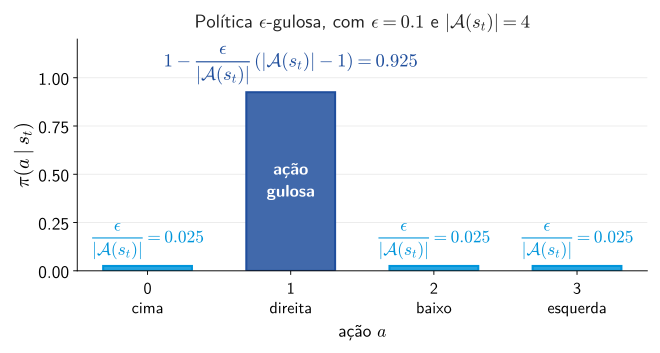

In [ ]:
show_figure("epsilon_gulosa")                                                   # Política epsilon-gulosa com epsilon = 0.1

> **On-policy** ($\pi_b = \pi_T$): $a_{t+1}$ é sorteada pela mesma política que o agente executa, e é ela que será executada no passo seguinte. Por isso os valores aprendidos são os dessa política, exploração incluída.

**Implementação.** Preencha os blocos marcados:

| Parte | Descrição | A implementar |
|---|---|---|
| `Params` | reúne os hiperparâmetros | — |
| `SarsaAgent` | guarda $q$, $\pi$ e as contagens de visitas; sorteia as ações; executa os dois passos | `update_policy`, `get_target_value` e `update_Q` |
| `run_episode_and_train` | executa um episódio, atualizando o agente a cada passo | o laço |
| `train_agent` | repete os episódios e registra as métricas | — |

### Hiperparâmetros

`Params` reúne os hiperparâmetros; `n_states` e `n_actions` vêm do ambiente.

| Campo | Hiperparâmetro |
|---|---|
| `n_episodes` | número de episódios, $N$ |
| `learning_rate` | taxa de aprendizado, $\alpha$ |
| `discount_factor` | fator de desconto, $\gamma$ |
| `epsilon` | parâmetro $\epsilon$ da política |

<details>
<summary><b>Detalhes:</b> como variar um hiperparâmetro com <code>_replace</code></summary>

Uma `NamedTuple` não pode ser alterada depois de criada, mas `params._replace(learning_rate=0.5)` devolve uma cópia de `params` com $\alpha$ trocado. Isso facilita variar um hiperparâmetro de cada vez, como nos itens 1 a 4 da tarefa.

</details>

In [ ]:
class Params(NamedTuple):
    n_states: int                                                               # Número de estados |S|
    n_actions: int                                                              # Número de ações |A|
    n_episodes: int                                                             # Número de episódios (N)
    learning_rate: float                                                        # Taxa de aprendizado (alpha)
    discount_factor: float                                                      # Fator de desconto (gamma)
    epsilon: float                                                              # Parâmetro da política epsilon-gulosa

### Agente

Implemente `update_policy`, `get_target_value` e `update_Q`; os demais métodos já estão prontos. O agente guarda:

| Atributo | Conteúdo |
|---|---|
| `self.Q` | estimativas $q_t(s,a)$, inicializada com zeros |
| `self.Pi` | política $\pi_t(a \mid s)$, inicializada uniformemente; a linha `self.Pi[s]` é o vetor de probabilidades das ações em `s` |
| `self.visit_counts` | número de visitas a cada par $(s,a)$ |
| `self.learning_rate`, `self.discount_factor`, `self.epsilon` | $\alpha$, $\gamma$, $\epsilon$ |
| `self.rng` | gerador de números aleatórios do agente |

As três matrizes têm shape `(n_states, n_actions)` e são indexadas por `[estado, ação]`. Nos métodos, os argumentos correspondem a:

| `obs` | `action` | `reward` | `next_obs` | `next_action` | `terminated` |
|:---:|:---:|:---:|:---:|:---:|:---:|
| $s_t$ | $a_t$ | $r_{t+1}$ | $s_{t+1}$ | $a_{t+1}$ | $s_{t+1}$ é terminal? |

<details>
<summary><b>Detalhes:</b> métodos prontos</summary>

- `get_greedy_action(obs)`: devolve $\arg\max_a q_t(s,a)$; em caso de empate, a ação de menor índice.
- `sample_action(obs)`: sorteia $a_t$ com as probabilidades de `self.Pi[obs]`, usando `self.rng`, e devolve `(action, is_exploratory)`, em que `is_exploratory` é `1` se a ação sorteada difere da gulosa e `0` caso contrário.
- `update(...)`: chama `update_Q` e `update_policy` e registra a visita ao par $(s_t, a_t)$.
- `policy(obs, deterministic)`: devolve a ação gulosa ou sorteia uma ação $\epsilon$-gulosa; é usado nas visualizações.

</details>

**A implementar:**

- `update_policy(obs)` $\to$ não devolve nada; refaz a linha `self.Pi[obs]`, o passo 2, pela fórmula $\epsilon$-gulosa da seção **Algoritmo**:
  - a ação gulosa recebe $1 - \dfrac{\epsilon}{|\mathcal{A}(s_t)|}\big(|\mathcal{A}(s_t)| - 1\big)$;
  - cada uma das demais ações recebe $\dfrac{\epsilon}{|\mathcal{A}(s_t)|}$, com $|\mathcal{A}(s_t)|$ = `self.n_actions`.
- `get_target_value(next_obs, next_action, reward, terminated)` $\to$ o alvo $\bar q_t$, um número real:
  - $\bar q_t = r_{t+1} + \gamma\, q_t(s_{t+1},a_{t+1})$, ou só $r_{t+1}$ se $s_{t+1}$ é terminal.
- `update_Q(obs, action, next_obs, next_action, reward, terminated)` $\to$ o erro TD $\delta_t$, um número real (escalar):
  - calcula o alvo com `get_target_value` e o erro TD: $\delta_t = q_t(s_t,a_t) - \bar q_t$;
  - atualiza o par visitado: $q_{t+1}(s_t,a_t) = q_t(s_t,a_t) - \alpha\,\delta_t$.

> **Atenção:**

> - Só `terminated` zera o futuro. No truncamento, $s_{t+1}$ não é terminal e $\gamma\, q_t(s_{t+1},a_{t+1})$ continua no alvo; por isso os métodos não recebem `truncated`.
> - Em `update_policy`, obtenha a ação gulosa com `self.get_greedy_action(obs)`: é a mesma que `sample_action` usa para marcar as ações exploratórias.

In [ ]:
class SarsaAgent:
    def __init__(self, params: Params, seed: int = SEED):
        # Número total de estados do ambiente (no CliffWalking: 48 estados, de 0 a 47)
        self.n_states = params.n_states
        # Número de ações possíveis que o agente pode escolher em cada estado (4 ações: 0=Cima, 1=Direita, 2=Baixo, 3=Esquerda)
        self.n_actions = params.n_actions
        # Taxa de aprendizado alpha (ex: 0.1): controla o quanto a nova informação substitui a estimativa antiga
        self.learning_rate = params.learning_rate
        # Fator de desconto gamma (ex: 0.9): pondera o peso das recompensas futuras em relação às imediatas
        self.discount_factor = params.discount_factor
        # Epsilon (ex: 0.1): probabilidade de tomar uma ação aleatória (exploração) em vez da gulosa
        self.epsilon = params.epsilon
        # Gerador pseudoaleatório com semente fixa para garantir reprodutibilidade nos experimentos
        self.rng = np.random.default_rng(seed)
        # Formato (shape) da tabela de valores de ação: 48 linhas (estados) x 4 colunas (ações)
        shape = (self.n_states, self.n_actions)
        # Tabela Q inicializada com zeros: armazena as estimativas q(s, a) para cada par estado-ação
        self.Q = np.zeros(shape)
        # Tabela da política Pi: inicializada de forma uniforme (1/4 = 0.25 para cada ação em todos os estados)
        self.Pi = np.full(shape, 1.0 / self.n_actions)
        # Matriz contadora de visitas a cada par (s, a), útil para análise de exploração
        self.visit_counts = np.zeros(shape)


    def get_greedy_action(self, obs: int) -> int:
        # np.argmax encontra o índice da coluna (ação) que tem o maior valor na linha do estado atual self.Q[obs]
        # ATENÇÃO: se houver empate entre valores, o np.argmax sempre retorna o primeiro índice (menor índice, 0 = CIMA)
        return int(np.argmax(self.Q[obs]))


    def update_policy(self, obs: int) -> None:
        # Passo 1: identifica qual é a melhor ação conhecida no estado atual obs
        melhor_acao = self.get_greedy_action(obs)

        # Passo 2: calcula a fatia de probabilidade de exploração dividida igualmente entre todas as ações (epsilon / |A|)
        prob_explorar = self.epsilon / self.n_actions
        # Passo 3: calcula a probabilidade da ação gulosa: (1 - epsilon) de certeza + a sua cota de exploração
        prob_gulosa = 1.0 - prob_explorar * (self.n_actions - 1)

        # Passo 4: preenche todas as ações do estado com a probabilidade mínima de exploração
        self.Pi[obs].fill(prob_explorar)

        # Passo 5: atribui a maior probabilidade (prob_gulosa) exclusivamente à melhor ação encontrada
        self.Pi[obs, melhor_acao] = prob_gulosa


    def sample_action(self, obs: int) -> Tuple[int, int]:
        # Sorteia uma ação de 0 a 3 de acordo com as probabilidades definidas na linha self.Pi[obs]
        action = int(self.rng.choice(self.n_actions, p=self.Pi[obs]))
        # Flag booleana (1 ou 0): verifica se a ação sorteada foi diferente da melhor ação (indicando exploração)
        is_exploratory = int(action != self.get_greedy_action(obs))
        # Retorna a ação escolhida e se ela foi ou não fruto de exploração aleatória
        return action, is_exploratory


    def policy(self, obs: int, deterministic: bool = False) -> int:
        # Se deterministic=True (modo deploy/avaliação pura): escolhe estritamente a ação gulosa (sem epsilon)
        if deterministic:
            return self.get_greedy_action(obs)
        # Se deterministic=False (modo exploração/treinamento): sorteia com base na distribuição epsilon-gulosa
        return self.sample_action(obs)[0]


    def get_target_value(self, next_obs: int, next_action: int, reward: float,
                         terminated: bool) -> float:
        # Se o próximo estado for terminal (chegou no alvo G ou caiu no penhasco):
        # Não existe futuro após a terminação, logo o alvo TD é apenas a recompensa imediata recebida
        if terminated:
            target_value = reward
        # Caso contrário (o episódio continua em terra firme):
        # O alvo é a recompensa imediata + o valor Q descontado da PRÓXIMA ação sorteada (on-policy!)
        else:
            target_value = reward + self.discount_factor * self.Q[next_obs, next_action]
        # Retorna o alvo TD calculado (q_bar_t)
        return target_value


    def update_Q(self, obs: int, action: int, next_obs: int, next_action: int,
                 reward: float, terminated: bool) -> float:
        # 1. Calcula o alvo TD usando a função get_target_value definida acima
        target_value = self.get_target_value(next_obs, next_action, reward, terminated)

        # 2. Calcula o erro TD (diferença entre o valor estimado atual e o novo alvo observado)
        td_error = self.Q[obs, action] - target_value

        # 3. Atualiza a tabela Q: dá um passo proporcional a alpha na direção que reduz o erro TD
        # Q(s, a) <- Q(s, a) - alpha * (Q(s, a) - target)  equivale a  Q(s, a) <- Q(s, a) + alpha * (target - Q(s, a))
        self.Q[obs, action] = self.Q[obs, action] - self.learning_rate * td_error

        # Retorna o erro TD para monitoramento
        return td_error


    def update(self, obs: int, action: int, next_obs: int, next_action: int,
               reward: float, terminated: bool) -> None:
        # 1. Atualiza a estimativa de valor do par (estado, ação) que acabou de ser executado
        self.update_Q(obs, action, next_obs, next_action, reward, terminated)
        # 2. Atualiza a política do estado s_t para que ela se torne epsilon-gulosa em relação aos novos valores Q
        self.update_policy(obs)
        # 3. Incrementa o contador de visitas do par (estado, ação)
        self.visit_counts[obs, action] += 1


### Episódio de treinamento

Implemente o laço de `run_episode_and_train`. O início já está pronto: `env.reset` devolve $s_0$, e a política sorteia $a_0$. Cada iteração do laço segue os passos da figura:

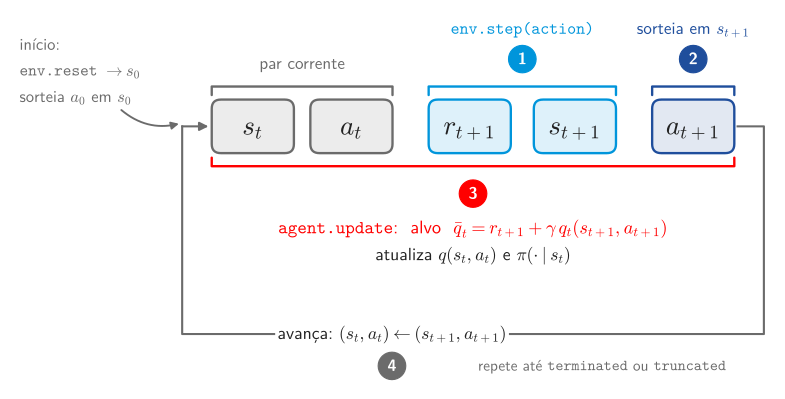

In [ ]:
show_figure("sarsa_passo")                                                      # Um passo do Sarsa

1. executa $a_t$ com `env.step`, que devolve $r_{t+1}$ e $s_{t+1}$;
2. sorteia $a_{t+1}$ em $s_{t+1}$;
3. atualiza o agente com $(s_t, a_t, r_{t+1}, s_{t+1}, a_{t+1})$, chamando `agent.update`;
4. avança: $(s_t, a_t) \leftarrow (s_{t+1}, a_{t+1})$.

O laço termina quando `terminated` ou `truncated` é `True`.

> **Atenção:**
> - Sorteie $a_{t+1}$ **antes** de atualizar: ela entra no alvo e é a ação executada no passo seguinte.
> - Passe `terminated` ao agente, e **não** `terminated or truncated`.
> - No passo 4 some em `n_exploratory_actions` o `is_exploratory` da ação **executada**, e não o da próxima.

**Retorno** (já pronto):

- `info["episode"]`: recompensa total, duração e tempo do episódio;
- `n_exploratory_actions`: número de ações não gulosas executadas;
- `terminated`: o sinal do último passo.

In [ ]:
def run_episode_and_train(agent: SarsaAgent, env: gym.Env, seed: int = SEED):
    # Reseta o ambiente para o estado inicial s_0 (estado 36 no CliffWalking) e obtém o dicionário de info
    obs, _info = env.reset(seed=seed)
    # Sorteia a primeira ação a_0 no estado inicial segundo a política epsilon-gulosa do agente
    action, is_exploratory = agent.sample_action(obs)

    # Variável de controle do laço do episódio
    episode_over = False
    # Contador de quantas ações exploratórias (aleatórias) foram tomadas ao longo do episódio
    n_exploratory_actions = 0
    # Flag booleana indicando se o agente atingiu um estado terminal (alvo ou queda no penhasco)
    terminated = False
    # Dicionário para armazenar métricas e informações retornadas pelo Gymnasium
    info = {}

    # O episódio continua enquanto não for terminal nem truncado (limite de 500 passos)
    while not episode_over:
        # 1. Executa a ação a_t no ambiente; o ambiente devolve o próximo estado s_{t+1},
        #    a recompensa r_{t+1}, se terminou naturalmente (terminated) ou por limite de tempo (truncated)
        next_obs, reward, terminated, truncated, step_info = env.step(action)

        # 2. CARACTERÍSTICA ON-POLICY DO SARSA:
        # Sorteia a próxima ação a_{t+1} no próximo estado s_{t+1} ANTES de atualizar a tabela Q
        next_action, next_is_exploratory = agent.sample_action(next_obs)

        # 3. Atualiza o agente com a transição completa (s_t, a_t, s_{t+1}, a_{t+1}, r_{t+1})
        # Esta linha chama internamente update_Q e update_policy
        agent.update(obs, action, next_obs, next_action, reward, terminated)

        # Contabiliza se a ação que acabou de ser executada (a_t) foi exploratória
        n_exploratory_actions += is_exploratory

        # 4. Avança o tempo no algoritmo: o próximo estado e ação tornam-se o estado e ação atuais
        obs = next_obs
        action = next_action
        is_exploratory = next_is_exploratory

        # O episódio encerra se atingir o alvo/penhasco (terminated) OU se estourar 500 passos (truncated)
        episode_over = terminated or truncated
        # Salva o dicionário de informações do último passo (contém a duração e recompensa total do RecordEpisodeStatistics)
        info = step_info

    # Retorna o resumo do episódio (recompensa acumulada e passos), total de ações exploratórias e se terminou
    return info["episode"], n_exploratory_actions, terminated


### Laço externo

`train_agent` já está pronta. Ela repete `run_episode_and_train` por `n_episodes` episódios, cada um com uma semente sorteada pelo gerador do agente, e devolve as séries numa `TrainingHistory`:

| Campo | Série, por episódio |
|---|---|
| `returns` | recompensa total |
| `lengths` | duração, em passos |
| `times` | tempo de execução, em segundos |
| `exploration_rates` | proporção de ações não gulosas executadas |
| `successes` | 1 se o episódio terminou no alvo; como o alvo é o único estado terminal do CliffWalking, o sucesso é o próprio `terminated` |

A barra de progresso mostra as médias dos últimos `STATS_BUFFER_LENGTH` episódios, calculadas com as filas do `RecordEpisodeStatistics`.

<details>
<summary><b>Detalhes:</b> a tupla nomeada <code>TrainingHistory</code></summary>

Cada campo pode ser acessado pelo nome, como em `history.returns`, e a tupla também pode ser desempacotada na ordem em que os campos foram definidos.

</details>

In [ ]:
class TrainingHistory(NamedTuple):
    returns: List[float]                                                        # Recompensa total (sem desconto) por episódio
    lengths: List[int]                                                          # Duração (passos) por episódio
    times: List[float]                                                          # Tempo de execução (s) por episódio
    exploration_rates: List[float]                                              # Proporção de ações exploratórias
    successes: List[int]                                                        # 1 se terminou no alvo, 0 caso contrário


def train_agent(agent: SarsaAgent, env: gym.Env,
                n_episodes: int) -> TrainingHistory:
    returns, lengths, times, exploration_rates, successes = [], [], [], [], []  # Históricos por episódio
    success_queue = deque(maxlen=env.return_queue.maxlen)                       # Janela recente de sucessos
    pbar = tqdm(range(n_episodes), desc="Treinando", unit="episódio")           # Barra de progresso

    for episode in pbar:
        seed = int(agent.rng.integers(2**32))                                   # Semente do episódio
        episode_data, n_exploratory_actions, terminated = run_episode_and_train(
            agent=agent, env=env, seed=seed)                                    # Treina em um episódio

        episode_length = int(episode_data["l"])                                 # Número de passos
        exploration_rate = n_exploratory_actions / episode_length               # Proporção de ações exploratórias
        success = int(terminated)                                               # No CliffWalking, terminar = chegar ao alvo

        returns.append(float(episode_data["r"]))                                # Recompensa total
        lengths.append(episode_length)                                          # Duração
        times.append(float(episode_data["t"]))                                  # Tempo
        exploration_rates.append(exploration_rate)                              # Exploração
        successes.append(success)                                               # Sucesso
        success_queue.append(success)                                           # Fila de sucessos recentes

        pbar.set_postfix({                                                      # Médias recentes na barra
            "recompensa_media": f"{np.mean(env.return_queue):.1f}",
            "passos_medio": f"{np.mean(env.length_queue):.1f}",
            "tempo_medio": f"{np.mean(env.time_queue):.3f}",
            "exploracao": f"{exploration_rate:.3f}",
            "sucesso": f"{np.mean(success_queue):.3f}",
        })

    return TrainingHistory(returns, lengths, times, exploration_rates, successes)

## Experimento

### Simulação

A célula abaixo treina o Sarsa na configuração base, com um ambiente (`train_env`) e um agente novos. O gerador do agente controla todos os sorteios e o CliffWalking é determinístico: com a mesma semente, a execução é reprodutível.

In [ ]:
params = Params(
    n_states=env.observation_space.n,                                           # 48 estados
    n_actions=env.action_space.n,                                               # 4 ações
    n_episodes=1000,                                                            # Número de episódios (N)
    learning_rate=0.1,                                                          # Taxa de aprendizado (alpha)
    discount_factor=0.9,                                                        # Fator de desconto (gamma)
    epsilon=0.1,                                                                # Parâmetro da política epsilon-gulosa
)

train_env = make_env()                                                          # Ambiente novo para o treinamento
agent = SarsaAgent(params, seed=SEED)                                           # Agente novo, com a semente do experimento
history = train_agent(agent, train_env, params.n_episodes)

Treinando:   0%|          | 0/1000 [00:00<?, ?episódio/s]

Os valores de estado da política aprendida saem das estimativas e da política finais: a média dos valores de ação, ponderada pelas probabilidades da política $\epsilon$-gulosa,

$$v(s) = \sum_a \pi(a \mid s)\, q(s,a)$$

In [ ]:
V = np.sum(agent.Pi * agent.Q, axis=1)                                          # v(s) = soma_a pi(a|s) q(s,a)

### Avaliação da política aprendida

A saída do Sarsa é a política $\epsilon$-gulosa aprendida, guardada em `agent.Pi`. `evaluate_policy`, já pronta, mede o desempenho dessa política: executa `n_episodes` episódios (100, por padrão) num ambiente novo, criado por `make_env`, sorteando cada ação com as probabilidades de `agent.Pi`, **sem** atualizar $q$ nem $\pi$. Ela devolve:

| Métrica | Significado |
|---|---|
| `chegada ao alvo` | proporção dos episódios que terminam no alvo |
| `recompensa total média` | média da recompensa total dos episódios |
| `duração média` | média da duração dos episódios, em passos |

Os sorteios usam um gerador próprio, criado com `seed`.

> **Atenção:** as curvas de `plot_results` vêm do treinamento, em que a política muda a cada atualização, inclusive dentro de um episódio. Elas mostram como o agente aprendeu; o desempenho da política aprendida é o que `evaluate_policy` mede, com $q$ e $\pi$ fixos.

In [ ]:
def evaluate_policy(agent: SarsaAgent, n_episodes: int = 100,
                    seed: int = SEED) -> pd.Series:
    rng = np.random.default_rng(seed)                                           # Gerador próprio da avaliação
    eval_env = make_env(render_mode=None)                                       # Ambiente novo, com o limite de passos
    returns, lengths, successes = [], [], []

    for _ in range(n_episodes):
        obs, _info = eval_env.reset(seed=int(rng.integers(2**32)))              # s_0
        terminated = truncated = False
        while not (terminated or truncated):
            action = int(rng.choice(agent.n_actions, p=agent.Pi[obs]))          # a ~ pi(.|s), a política aprendida
            obs, _reward, terminated, truncated, info = eval_env.step(action)   # Sem agent.update: q e pi fixos
        returns.append(float(info["episode"]["r"]))                             # Recompensa total
        lengths.append(int(info["episode"]["l"]))                               # Duração
        successes.append(int(terminated))                                       # 1 se chegou ao alvo

    return pd.Series({
        "chegada ao alvo": np.mean(successes),
        "recompensa total média": np.mean(returns),
        "duração média": np.mean(lengths),
    })

Na configuração base:

In [ ]:
evaluate_policy(agent)                                                          # Política aprendida, com q e pi fixos

,0
chegada ao alvo,1.00
recompensa total média,-21.33
duração média,17.37


### Visualização

As figuras vêm das funções do `rl_utils`, importadas no início do notebook:

| Função | Descrição|
|---|---|
| `plot_results` | recompensa total, duração, taxa de exploração e sucesso por episódio, com a média móvel de `STATS_BUFFER_LENGTH` episódios |
| `simulate_trajectory` | executa um episódio num ambiente próprio e devolve a trajetória; por padrão, a trajetória gulosa (definida abaixo) |
| `plot_trajectory` | o caminho sobre a grade, com o penhasco em vermelho e o alvo em verde |
| `show_one_episode` | a animação de um episódio com a política aprendida ($\epsilon$-gulosa), exploração incluída |
| `plot_tabular` | mapas de calor de $q(s,a)$, $\pi(a \mid s)$ ou $v(s)$, escolhidos pelo argumento `kind` |
| `plot_policy_distributions` | as probabilidades das quatro ações em cada estado |
| `plot_comparison` | as médias móveis de várias execuções num só gráfico, com legenda (usada na tarefa) |

> **Atenção:** cada mapa de calor calcula a escala de cores a partir dos próprios valores, e a mesma cor pode representar números diferentes em figuras diferentes. Para comparar figuras, use os números anotados nas células.

<details>
<summary><b>Detalhes:</b> escalas dos eixos e gráficos lado a lado</summary>

- Em `plot_results`, os eixos da recompensa total e da duração usa a escala `symlog`, linear entre $-100$ e $100$ e logarítmica fora dessa faixa.
- `plot_comparison` e `plot_trajectory` aceitam o argumento `ax`, o painel da figura em que o gráfico é desenhado. Com `ax`, elas não chamam `plt.show()`, e a figura é exibida uma vez só, ao final. Para as curvas de duração e de recompensa total lado a lado:

      fig, axs = plt.subplots(1, 2, figsize=(18, 5))
      plot_comparison(histories, metric="lengths", ax=axs[0])
      plot_comparison(histories, metric="returns", ax=axs[1])
      plt.tight_layout()
      plt.show()

  em que `histories` é um dicionário que associa o rótulo de cada configuração (o texto da legenda) ao histórico devolvido por `train_agent`.

</details>

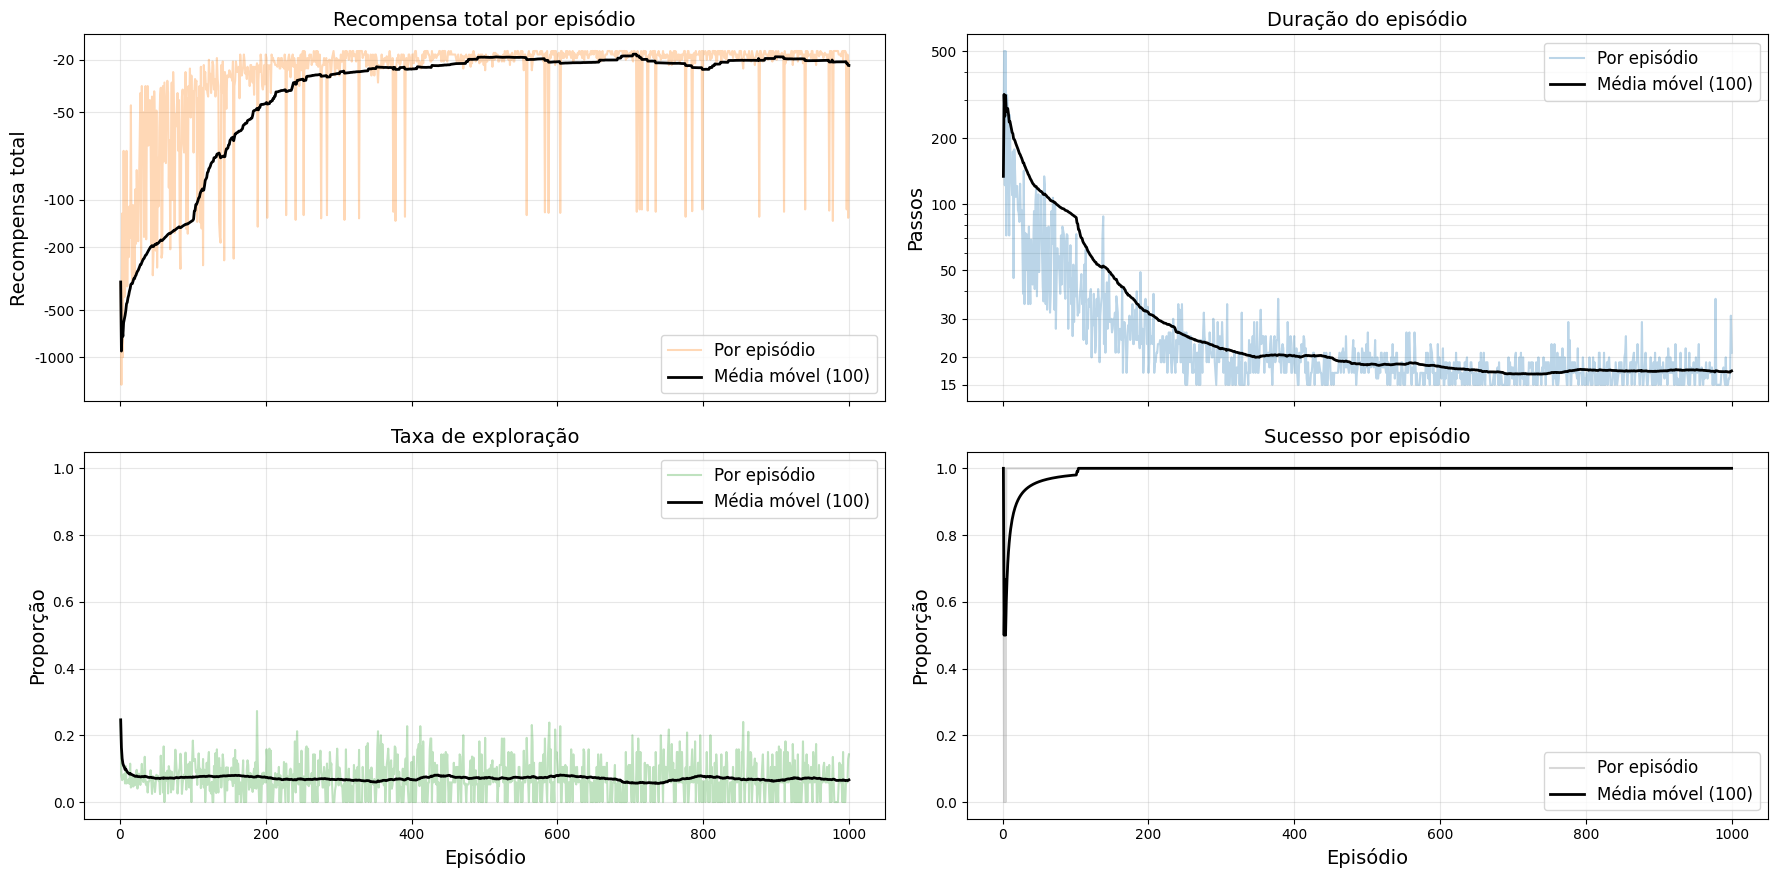

In [ ]:
df_results = plot_results(                                                      # Métricas da configuração base
    history.returns, history.lengths, history.exploration_rates,
    history.successes, window=STATS_BUFFER_LENGTH)

**Trajetória gulosa:** a trajetória obtida executando, em cada estado, a ação mais provável da política aprendida, $\arg\max_a q(s,a)$. Ela ajuda a ler o que o agente aprendeu, mas não é a saída do Sarsa: a política aprendida é a $\epsilon$-gulosa, avaliada por `evaluate_policy`. Com $\epsilon = 0.1$, a ação gulosa tem probabilidade 0.925 em cada estado, e um episódio segue uma trajetória gulosa de 15 passos.

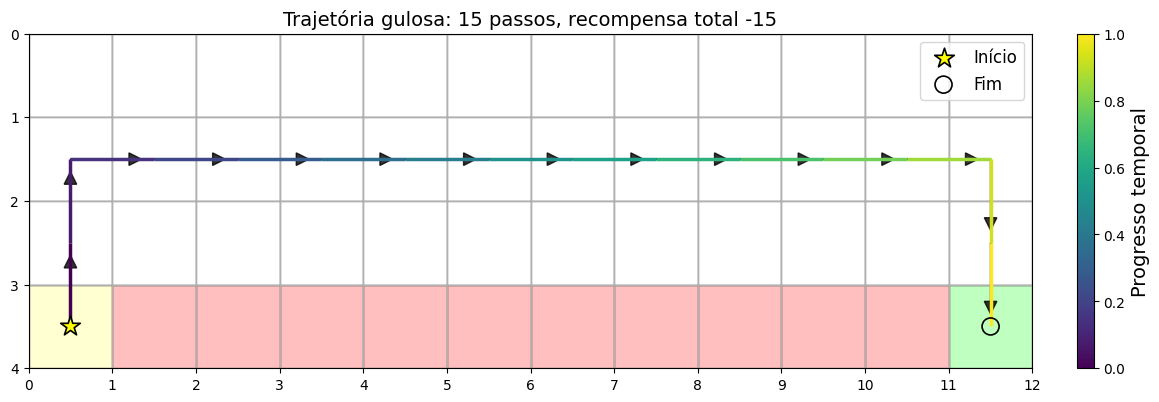

In [ ]:
states, actions, rewards = simulate_trajectory(agent, ENV_ID)                   # Trajetória gulosa (sem exploração)
title = (f"Trajetória gulosa: {len(actions)} passos, "
         f"recompensa total {sum(rewards):.0f}")
_ = plot_trajectory(ENV_ID, states, title=title)

In [ ]:
show_one_episode(agent.policy, ENV_ID, seed=SEED)                               # Animação com a política epsilon-gulosa

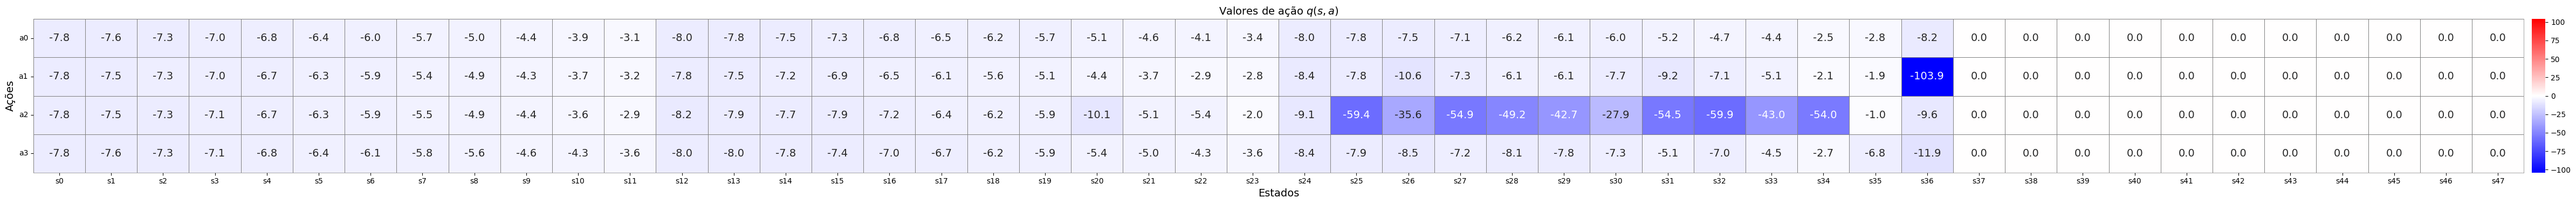

In [ ]:
_ = plot_tabular(agent.Q, kind="Q")                                             # q: ndarray (n_estados, n_acoes)

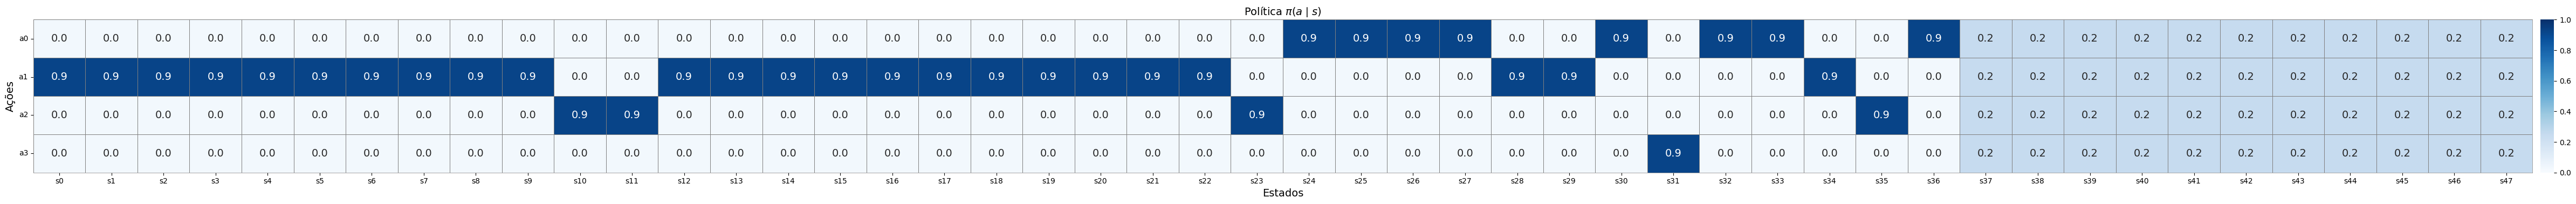

In [ ]:
_ = plot_tabular(agent.Pi, kind="Pi")                                           # pi: ndarray (n_estados, n_acoes)

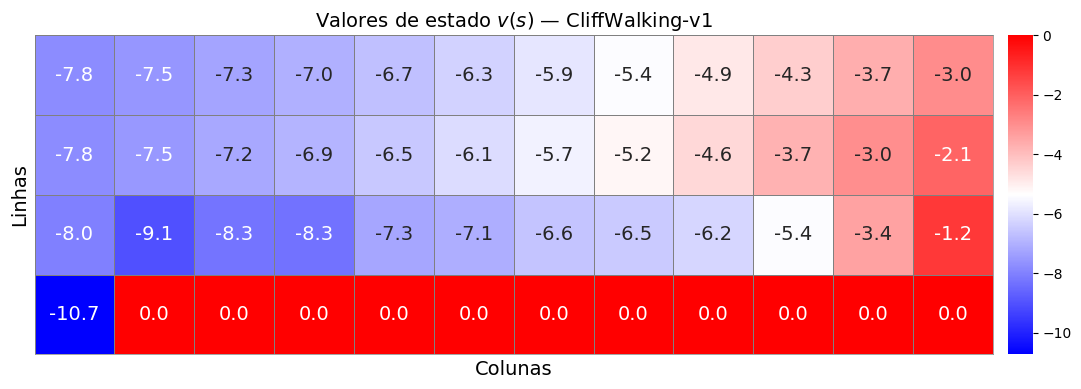

In [ ]:
_ = plot_tabular(V, kind="V", env_id=ENV_ID, center_zero=False)                 # v: ndarray (n_estados,)

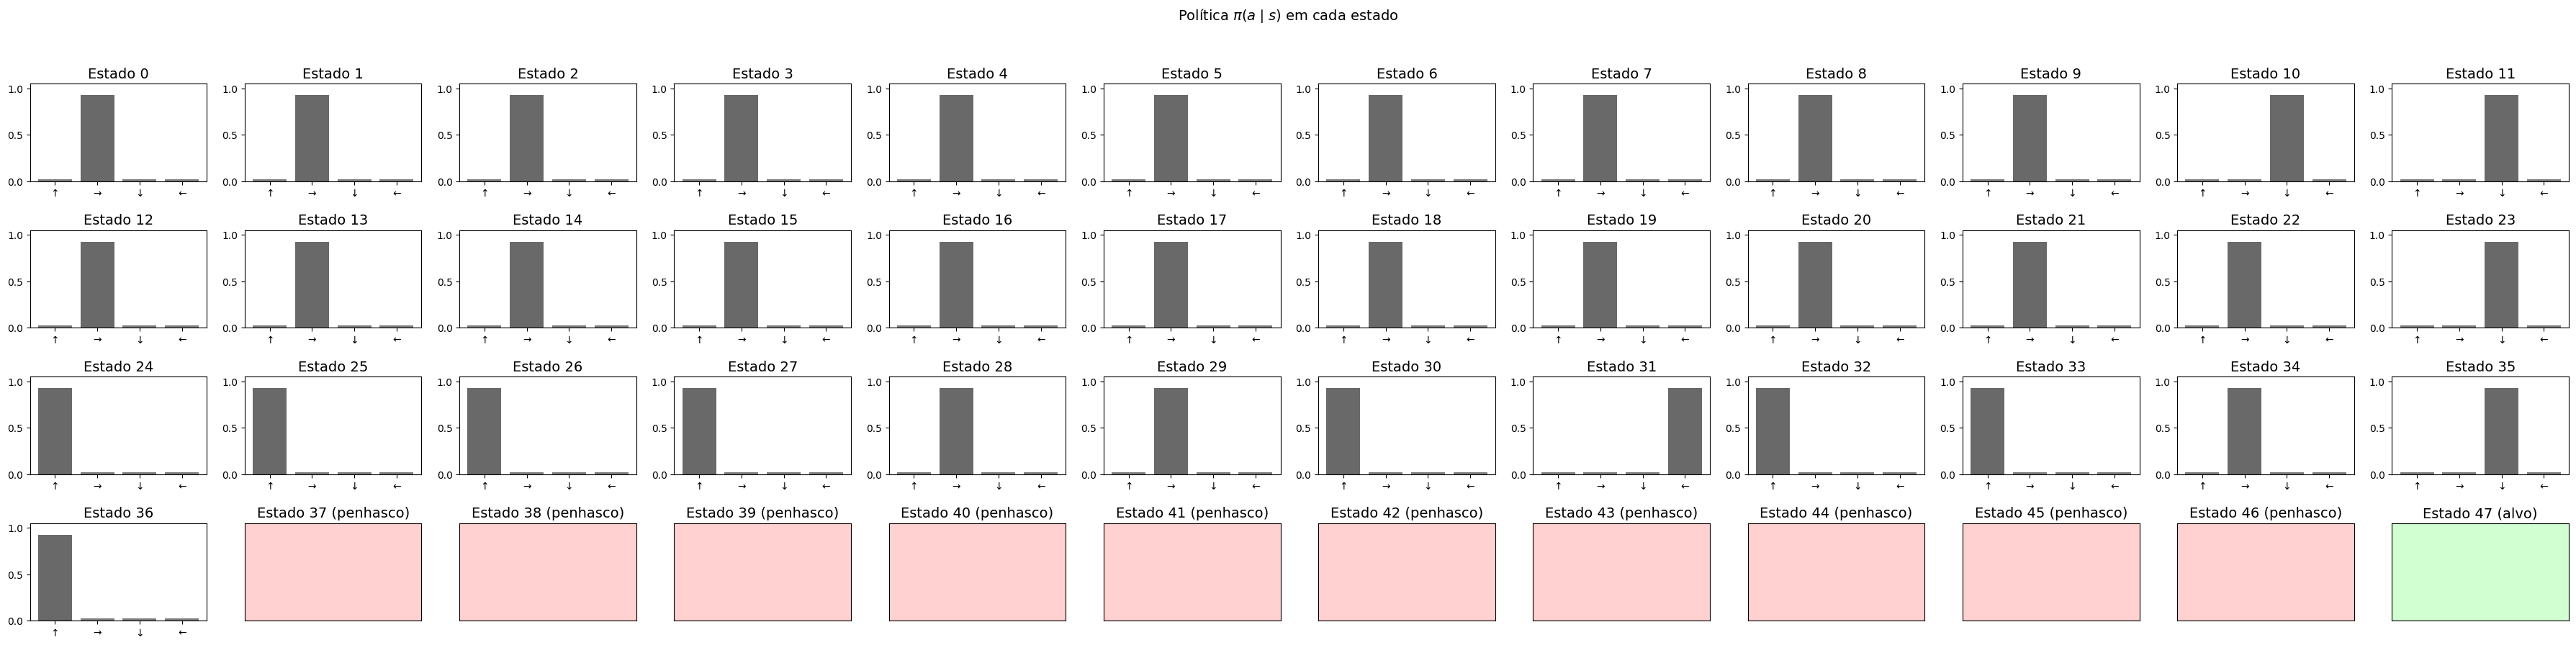

In [ ]:
plot_policy_distributions(agent.Pi, ENV_ID)                                     # pi(.|s) em cada estado

# Tarefa (em trios):

Responda no próprio notebook. Cada item tem uma seção **Resposta**, com:

- uma célula de código, para os experimentos, as figuras e as tabelas;
- uma célula de texto, com **uma resposta por pergunta**, identificada pelo mesmo rótulo: (a), (b), ...

Acrescente células se precisar, mas não apague nem reordene os enunciados.

**Configuração base (baseline)**

| Parâmetro | Valor |
|---|---|
| ambiente | `CliffWalking-v1`, com `MAX_EPISODE_STEPS = 500` |
| número de episódios, $N$ | `n_episodes = 1000` |
| taxa de aprendizado, $\alpha$ | `learning_rate = 0.1` |
| fator de desconto, $\gamma$ | `discount_factor = 0.9` |
| parâmetro $\epsilon$ | `epsilon = 0.1` |
| janela das médias móveis | `STATS_BUFFER_LENGTH = 100` episódios |
| semente | `SEED = 42`, com ambiente (`make_env`) e agente novos em cada execução |

**Mostrar**

- **Figuras:**
  - configuração base: as figuras da seção **Visualização** (curvas de `plot_results`, trajetória gulosa e heatmaps de $q(s,a)$, $\pi(a \mid s)$ e $v(s)$);
  - itens 1 a 4: as curvas de duração e de recompensa total de todas as execuções do item, sobrepostas e com legenda (`plot_comparison`), e a trajetória gulosa de cada execução.
- **Tabela**, para cada execução dos itens 1 a 4:
  - chegada ao alvo, recompensa total média e duração média da política aprendida, medidas com `evaluate_policy`;
  - passos e recompensa total da trajetória gulosa.
- **Discussão:** uma resposta curta por pergunta, na célula de texto da **Resposta**.

**Entregáveis**

- Um notebook (`.ipynb`) por laboratório da Unidade 2, entregue ao fim da unidade, com a tarefa respondida nas seções **Resposta**. Nesta unidade não há relatório em PDF.
- O notebook deve **executar do início ao fim sem erros** em um kernel novo (*Restart & Run All*), com as saídas exibidas correspondendo a essa execução. Notebooks que não executarem por completo serão penalizados.
- A entrega é **única por grupo**, com os integrantes identificados no início do notebook.

### 🧭 Guia de Estudo e Apresentação (Laboratório 7 - SARSA)

<div style="padding: 12px; border-left: 5px solid #27ae60; background-color: #f4fbf7; margin-bottom: 15px;">
  <h4 style="color: #27ae60; margin-top: 0;">🟢 O QUE VOCÊ DEVE DETALHAR E DESTACAR (Fale com confiança):</h4>
  <ul style="color: #1e824c; line-height: 1.6;">
    <li><b>SARSA é On-Policy:</b> O agente aprende o valor da política que ele realmente joga (a política epsilon-gulosa). No alvo de atualização, ele usa a próxima ação sorteada <i>a_{t+1}</i>.</li>
    <li><b>Caminho Seguro vs Caminho Curto:</b> Mostre a figura da trajetória gulosa. Explique que o caminho mais curto na grade tem 13 passos (rente ao penhasco), mas o SARSA escolhe a rota mais longa e segura pelo topo (15 a 17 passos), porque andar na beirada traz risco constante de queda (-100) durante a exploração.</li>
    <li><b>Diferença entre Trajetória Gulosa (-15) e Política Aprendida (-21.33):</b> A trajetória gulosa é determinística (epsilon=0, sem erros). A política aprendida (evaluate_policy) ainda executa ações aleatórias com probabilidade epsilon=0.1, sofrendo pequenos desvios.</li>
  </ul>
</div>

<div style="padding: 12px; border-left: 5px solid #c0392b; background-color: #fdf7f7;">
  <h4 style="color: #c0392b; margin-top: 0;">🔴 O QUE PODE GERAR DÚVIDA / PEGADINHAS DA BANCA (Atenção redobrada):</h4>
  <ul style="color: #962d22; line-height: 1.6;">
    <li><b>Por que o np.argmax escolhe a ação de menor índice nos empates?</b> Se os valores Q estão empatados (ex: todos iguais a -1 ou 0), o numpy sempre escolhe a primeira ação (índice 0 = CIMA). Isso é crucial para entender por que gamma=0.0 ou 0.5 fica preso subindo para a parede superior!</li>
    <li><b>O agente realmente 'sabe' que o penhasco existe antes de cair?</b> NÃO! No início, a tabela Q é zerada. Ele só descobre o perigo ao cair e receber a recompensa imediata de -100, que é propagada para trás ao longo dos episódios.</li>
    <li><b>Por que alpha=1.0 não converge perfeitamente?</b> Com alpha=1.0, o agente descarta todo o aprendizado passado e substitui pelo alvo imediato. Como as ações exploratórias são aleatórias, qualquer queda ou desvio destrói o valor estável do estado.</li>
  </ul>
</div>


## 0. Implementação

<div style="padding: 10px; border-left: 5px solid #27ae60; background-color: #f4fbf7; margin-bottom: 10px;">
  <b style="color: #27ae60;">🟢 O QUE DETALHAR NA TAREFA 0:</b>
  <ul style="color: #1e824c; margin-bottom: 0;">
    <li><b>(a) Por que o caminho é mais longo (15 passos pelo topo) em vez de 13 passos na beirada?</b> Explique que o SARSA é <i>on-policy</i>. Seu alvo TD usa a próxima ação real {t+1}$ da política $\epsilonhBcgulosa. Como há risco de tropeçar no abismo ao explorar, os estados na beirada recebem penalidades severas, fazendo o agente escolher contornar pelo alto.</li>
    <li><b>(b) Por que a trajetória gulosa dá -15 e a política aprendida dá -21.33?</b> A trajetória gulosa é determinística ($\epsilon=0$), executando a rota ótima segura sem errar. Já o <code>evaluate_policy</code> testa a política $\epsilonhBcgulosa com 10% de exploração, onde ações aleatórias geram desvios adicionais.</li>
  </ul>
</div>
<div style="padding: 10px; border-left: 5px solid #c0392b; background-color: #fdf7f7;">
  <b style="color: #c0392b;">🔴 O QUE PODE GERAR DÚVIDA / PEGADINHA:</b>
  <p style="color: #962d22; margin: 5px 0 0 0;">Se a banca perguntar: <i>"Se a rota gulosa é determinística e nunca erra, por que o SARSA não aprende o caminho de 13 passos?"</i>. <b>Resposta:</b> Porque a tabela Q foi atualizada durante o treino sob a política $\epsilonhBcgulosa. O SARSA não aprende a função valor da política ótima pura (*$), mas sim a função valor da política exploratória (\pi$).</p>
</div>

**Experimento:** implemente `update_policy`, `get_target_value` e `update_Q` de `SarsaAgent` e o laço de `run_episode_and_train`, e execute a seção **Experimento**: treinamento na configuração base, avaliação da política aprendida e visualização.

**Perguntas:**

- **(a)** Compare a trajetória gulosa com o caminho mais curto (13 passos, rente ao penhasco). O que, na forma como o Sarsa calcula o alvo TD $\bar q_t$, explica a diferença?
- **(b)** Compare a recompensa total média da política aprendida com a recompensa total da trajetória gulosa. Por que são diferentes?

### Resposta

In [ ]:
# As imagens, tabelas e dados estão nas seções 'Experimento' e 'Visualização'.

- **(a)**: Essa diferença ocorre porque o Sarsa é um algoritmo on-policy. O seu alvo TD $\bar q_t$ é calculado utilizando a próxima ação ($a_{t+1}$) ditada pela própria política comportamental $\epsilon$-gulosa, que inclui ações exploratórias aleatórias. Como o risco de cair no penhasco durante a exploração é alto, o Sarsa aprende valores $Q$ menores para os estados próximos à borda, resultando num caminho mais longo, porém mais seguro.
- **(b)**: Comparando as duas, vemos que a recompensa total média da política aprendida (-21.33) é inferior à da trajetória gulosa (-15). Isto se deve ao fato de a trajetória gulosa seguir sempre a melhor ação conhecida de forma determinística (exploração zero). Em contrapartida, a política aprendida continua a ser $\epsilon$-gulosa, o que significa que o agente, em média, toma ações aleatórias sub-ótimas em 10% das vezes (devido ao $\epsilon = 0.1$), o que alonga a duração do episódio e diminui a recompensa total.

## 1. Efeito da taxa de aprendizado ($\alpha$)

<div style="padding: 10px; border-left: 5px solid #27ae60; background-color: #f4fbf7; margin-bottom: 10px;">
  <b style="color: #27ae60;">🟢 O QUE DETALHAR NA TAREFA 1 (alpha):</b>
  <ul style="color: #1e824c; margin-bottom: 0;">
    <li><b>Efeito do alpha:</b> $lpha=0.01$ é muito lento (apenas 12% de sucesso em 1000 episódios). $lpha=0.1$ atinge 100% de sucesso de forma estável. $lpha=0.5$ e $lpha=1.0$ aprendem mais rápido no início, mas oscilam mais.</li>
    <li><b>Por que trajetórias gulosas podem ser diferentes?</b> O SARSA possui estocasticidade no treino (sorteio de ações aleatórias) e os empates na tabela Q dependem da ordem com que os caminhos seguros no topo foram visitados.</li>
  </ul>
</div>
<div style="padding: 10px; border-left: 5px solid #c0392b; background-color: #fdf7f7;">
  <b style="color: #c0392b;">🔴 O QUE PODE GERAR DÚVIDA / PEGADINHA:</b>
  <p style="color: #962d22; margin: 5px 0 0 0;">Por que $lpha=1.0$ não é a melhor escolha se ele aprende imediatamente? <b>Resposta:</b> Porque em aprendizado por reforço com exploração, o retorno é estocástico. Com $lpha=1.0$, o agente descarta toda a média histórica e substitui pelo último alvo. Um único tropeço aleatório zera o valor positivo acumulado de um estado seguro.</p>
</div>

**Experimento:** treine o Sarsa para $\alpha \in \{0.01,\ 0.1,\ 0.5,\ 1.0\}$, com um ambiente e um agente novos para cada valor, fixando:

- $\gamma = 0.9$;
- $\epsilon = 0.1$;
- `n_episodes = 1000`;
- os demais parâmetros do baseline.

Crie os parâmetros de cada execução a partir do baseline com `_replace`:

    params_exp = params._replace(learning_rate=0.5)

**Perguntas:**

- **(a)** Como $\alpha$ afetou o aprendizado? Explique por quê.
- **(b)** A trajetória gulosa é a mesma em todas as execuções? Por que o mesmo algoritmo pode chegar a trajetórias diferentes?

### Resposta

Sarsa com alpha (α) = 0.01


Treinando:   0%|          | 0/1000 [00:00<?, ?episódio/s]

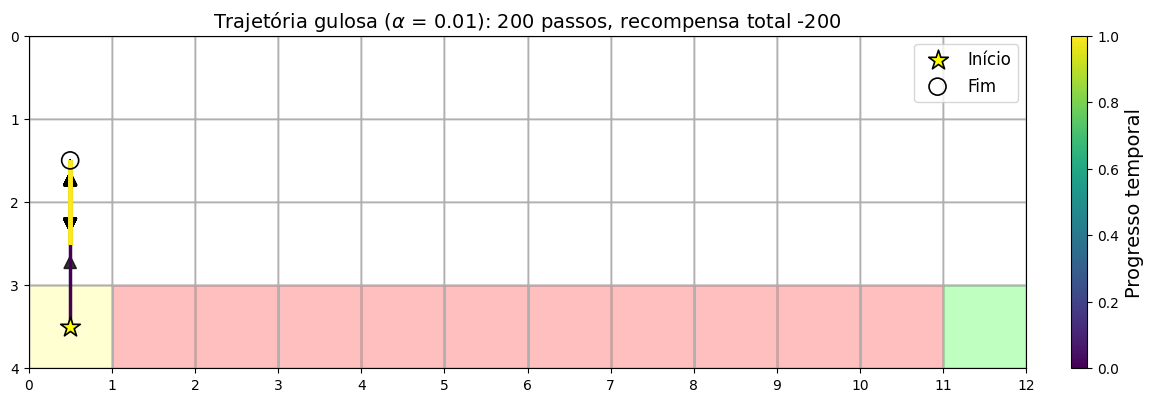

Sarsa com alpha (α) = 0.1


Treinando:   0%|          | 0/1000 [00:00<?, ?episódio/s]

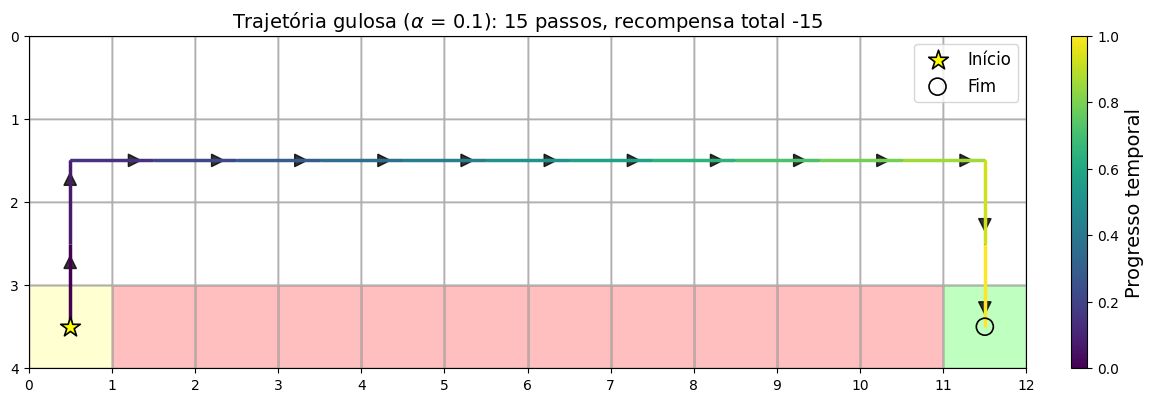

Sarsa com alpha (α) = 0.5


Treinando:   0%|          | 0/1000 [00:00<?, ?episódio/s]

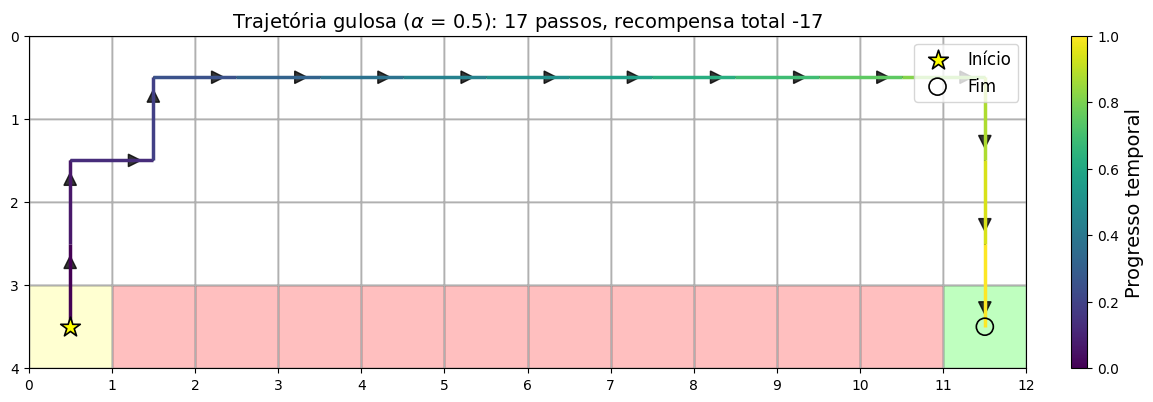

Sarsa com alpha (α) = 1.0


Treinando:   0%|          | 0/1000 [00:00<?, ?episódio/s]

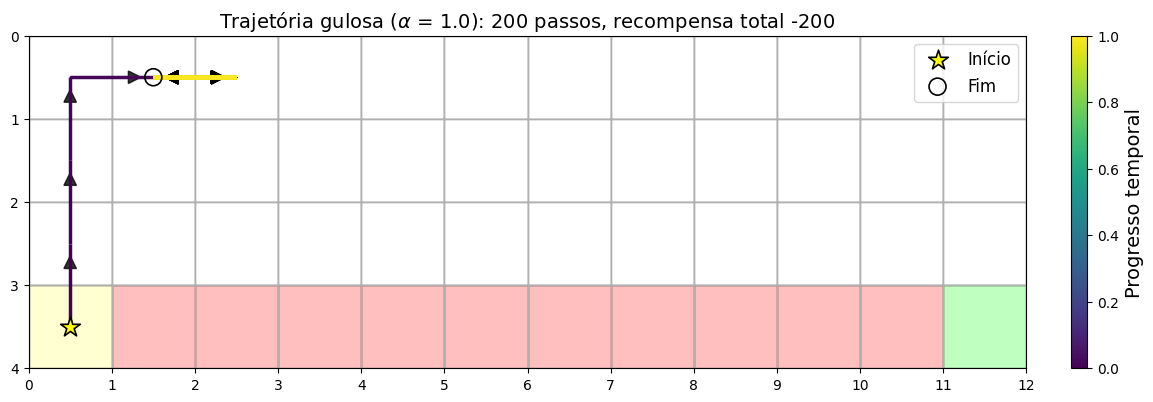

COMPARAÇÃO DAS CURVAS DE APRENDIZADO


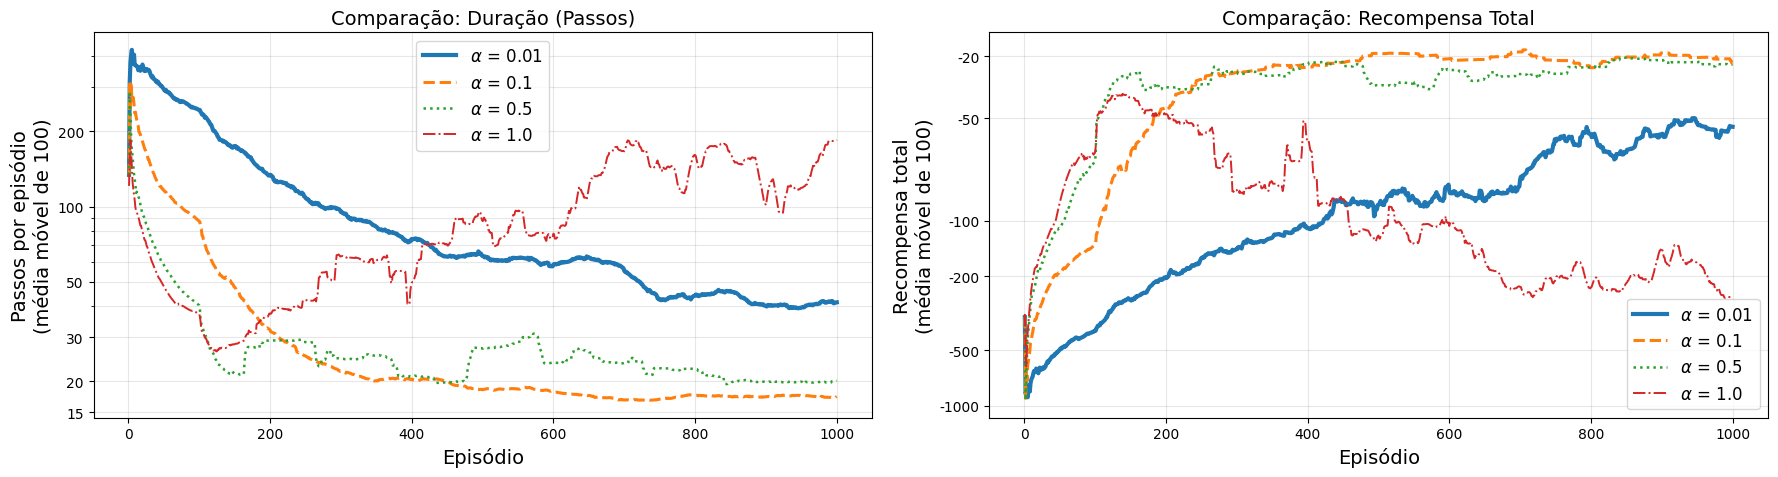

TABELA DE RESULTADOS (AVALIAÇÃO E TRAJETÓRIA GULOSA)


,Chegada ao Alvo (Aprendida),Rec. Total Média (Aprendida),Duração Média (Aprendida),Passos (Gulosa),Rec. Total (Gulosa)
alpha,,,,,
0.01,0.12,-512.22,479.55,200,-200.0
0.10,1.00,-21.33,17.37,15,-15.0
0.50,1.00,-24.19,19.24,17,-17.0
1.00,1.00,-115.85,107.93,200,-200.0


In [ ]:
alphas = [0.01, 0.1, 0.5, 1.0]
histories_alpha = {}
resultados_alpha = []

for alpha in alphas:
    print(f"Sarsa com alpha (α) = {alpha}")

    # 1. Criação dos novos parâmetros a partir do baseline
    params_exp = params._replace(learning_rate=alpha)

    # 2. Instanciação de ambiente e agente novos para cada execução
    train_env = make_env()
    agent = SarsaAgent(params_exp, seed=SEED)

    # 3. Treinamento
    history = train_agent(agent, train_env, params_exp.n_episodes)
    histories_alpha[f"$\\alpha$ = {alpha}"] = history

    # 4. Avaliação da política aprendida
    eval_metrics = evaluate_policy(agent)

    # 5. Avaliação da trajetória gulosa
    states, actions, rewards = simulate_trajectory(agent, ENV_ID)
    passos_gulosos = len(actions)
    recompensa_gulosa = sum(rewards)

    # 6. Registro dos dados para a tabela final
    resultados_alpha.append({
        "alpha": alpha,
        "Chegada ao Alvo (Aprendida)": eval_metrics["chegada ao alvo"],
        "Rec. Total Média (Aprendida)": eval_metrics["recompensa total média"],
        "Duração Média (Aprendida)": eval_metrics["duração média"],
        "Passos (Gulosa)": passos_gulosos,
        "Rec. Total (Gulosa)": recompensa_gulosa
    })

    # 7. Figura da trajetória gulosa para esta execução
    title = f"Trajetória gulosa ($\\alpha$ = {alpha}): {passos_gulosos} passos, recompensa total {recompensa_gulosa:.0f}"
    _ = plot_trajectory(ENV_ID, states, title=title)

# 8. Curvas de comparação (duração e recompensa total) sobrepostas
print("COMPARAÇÃO DAS CURVAS DE APRENDIZADO")
fig, axs = plt.subplots(1, 2, figsize=(18, 5))
plot_comparison(histories_alpha, metric="lengths", ax=axs[0])
axs[0].set_title("Comparação: Duração (Passos)")

plot_comparison(histories_alpha, metric="returns", ax=axs[1])
axs[1].set_title("Comparação: Recompensa Total")

plt.tight_layout()
plt.show()

# 9. Exibição da Tabela Final
print("TABELA DE RESULTADOS (AVALIAÇÃO E TRAJETÓRIA GULOSA)")
df_alpha = pd.DataFrame(resultados_alpha)
df_alpha.set_index("alpha", inplace=True)
display(df_alpha)

- **(a)**: $\alpha$ (taxa de aprendizado) controla o peso da nova informação na atualização dos valores $Q$. Valores muito baixos (como $\alpha=0.01$) deixam o aprendizado muito lento, impedindo que o agente convirja nos 1000 episódios, resultando em apenas 12% de sucesso na chegada ao alvo. O valor $\alpha=0.1$ proporcionou o melhor equilíbrio, com a convergência mais rápida e estável para recompensas altas. Já valores altos ($\alpha=0.5$ e $\alpha=1.0$) causam instabilidade e flutuações, pois o agente sobrescreve rapidamente o conhecimento acumulado com observações ruidosas recentes.
- **(b)**: Não, as trajetórias gulosas variam entre as execuções. O mesmo algoritmo chega a trajetórias diferentes porque a taxa com que os valores $Q(s,a)$ são atualizados altera a matriz de conhecimento final. Dependendo do $\alpha$, as explorações aleatórias pesam mais ou menos na atualização, fazendo com que o agente estabilize em ótimos locais diferentes, indo por rotas mais longas e seguras ou sofra divergência e não aprenda rota nenhuma.

## 2. Efeito do fator de desconto ($\gamma$)

<div style="padding: 10px; border-left: 5px solid #27ae60; background-color: #f4fbf7; margin-bottom: 10px;">
  <b style="color: #27ae60;">🟢 O QUE DETALHAR NA TAREFA 2 (gamma):</b>
  <ul style="color: #1e824c; margin-bottom: 0;">
    <li><b>Miopia temporal:</b> Para $\gamma=0.0$ e $\gamma=0.5$, o agente foca no curto prazo e não consegue chegar ao alvo (0% de sucesso, atinge o limite de 500 passos).</li>
    <li><b>Visão de longo prazo:</b> Para $\gamma=0.9$ e $\gamma=0.99$, o agente valoriza o futuro, conseguindo propagar o retorno até a origem e aprendendo a rota com 100% de sucesso.</li>
  </ul>
</div>
<div style="padding: 10px; border-left: 5px solid #c0392b; background-color: #fdf7f7;">
  <b style="color: #c0392b;">🔴 O QUE PODE GERAR DÚVIDA / PEGADINHA:</b>
  <p style="color: #962d22; margin: 5px 0 0 0;">Por que o agente com $\gamma=0$ sobe repetidamente para a parede superior? <b>Resposta:</b> Como todos os passos normais dão recompensa -1, para $\gamma=0$ todas as 4 ações têm valor -1. Como há empate absoluto em todas as ações, o <code>np.argmax</code> escolhe o menor índice, que é 0 (CIMA). Ele bate na borda superior e fica preso até truncar.</p>
</div>

**Experimento:** treine o Sarsa para $\gamma \in \{0,\ 0.5,\ 0.9,\ 0.99\}$, com um ambiente e um agente novos para cada valor, fixando:

- $\alpha = 0.1$;
- $\epsilon = 0.1$;
- `n_episodes = 1000`;
- os demais parâmetros do baseline.

**Perguntas:**

- **(a)** Como $\gamma$ afetou a trajetória gulosa? Explique por quê.

### Resposta

Sarsa com gamma (γ) = 0.0


Treinando:   0%|          | 0/1000 [00:00<?, ?episódio/s]

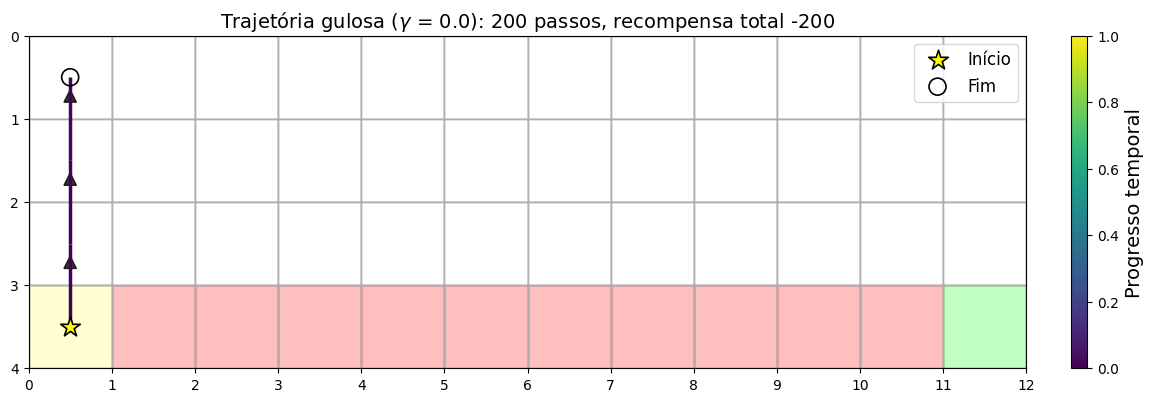

Sarsa com gamma (γ) = 0.5


Treinando:   0%|          | 0/1000 [00:00<?, ?episódio/s]

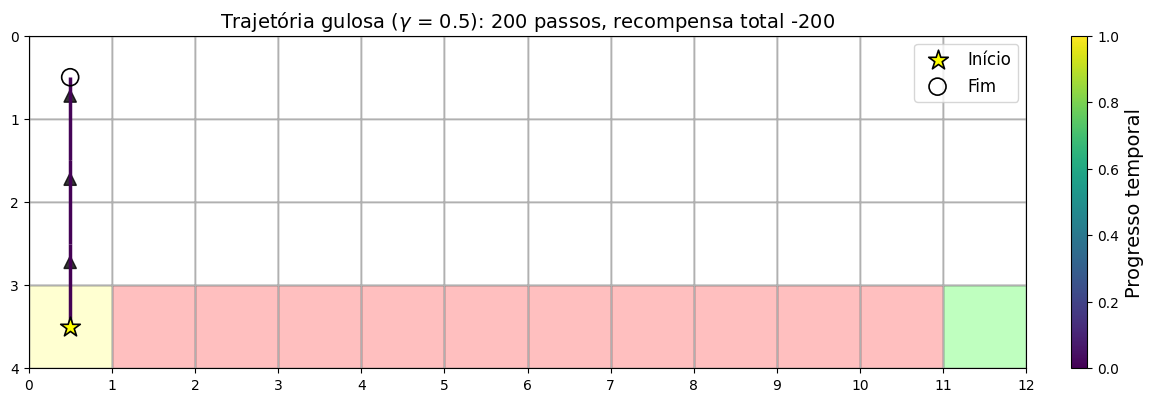

Sarsa com gamma (γ) = 0.9


Treinando:   0%|          | 0/1000 [00:00<?, ?episódio/s]

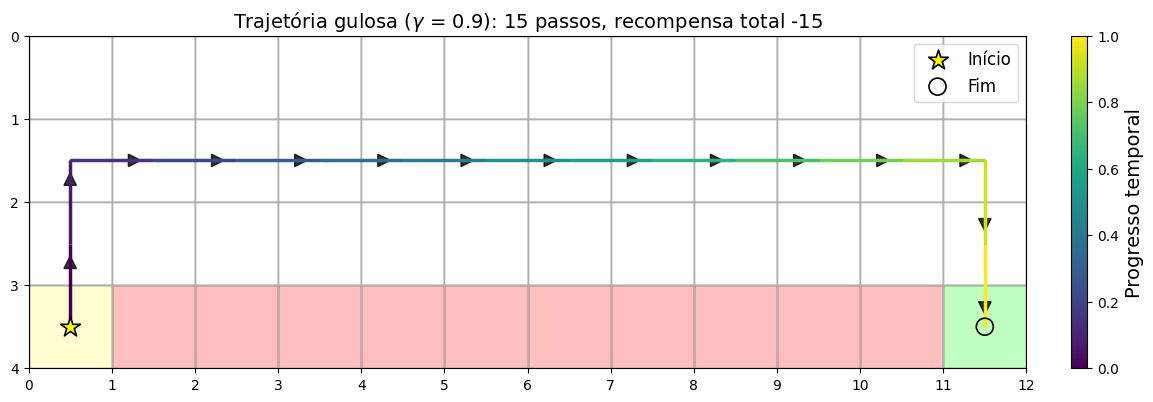

Sarsa com gamma (γ) = 0.99


Treinando:   0%|          | 0/1000 [00:00<?, ?episódio/s]

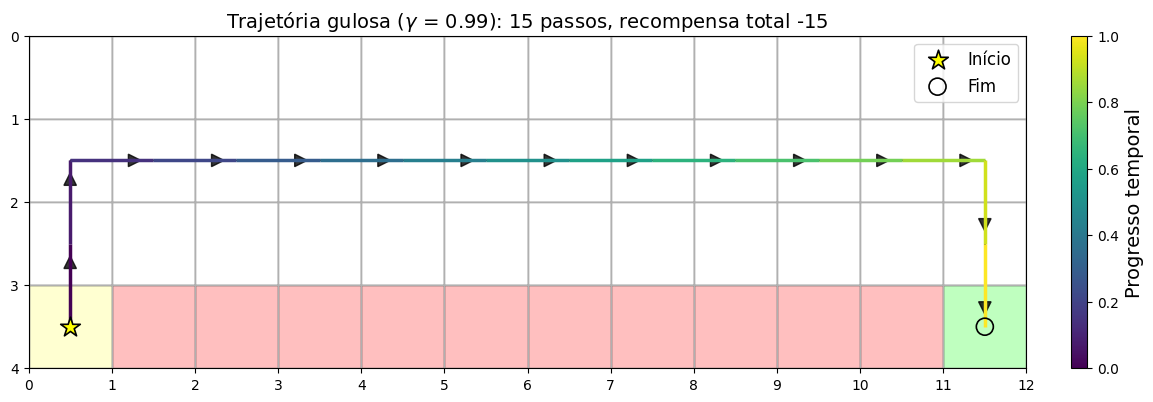

COMPARAÇÃO DAS CURVAS DE APRENDIZADO


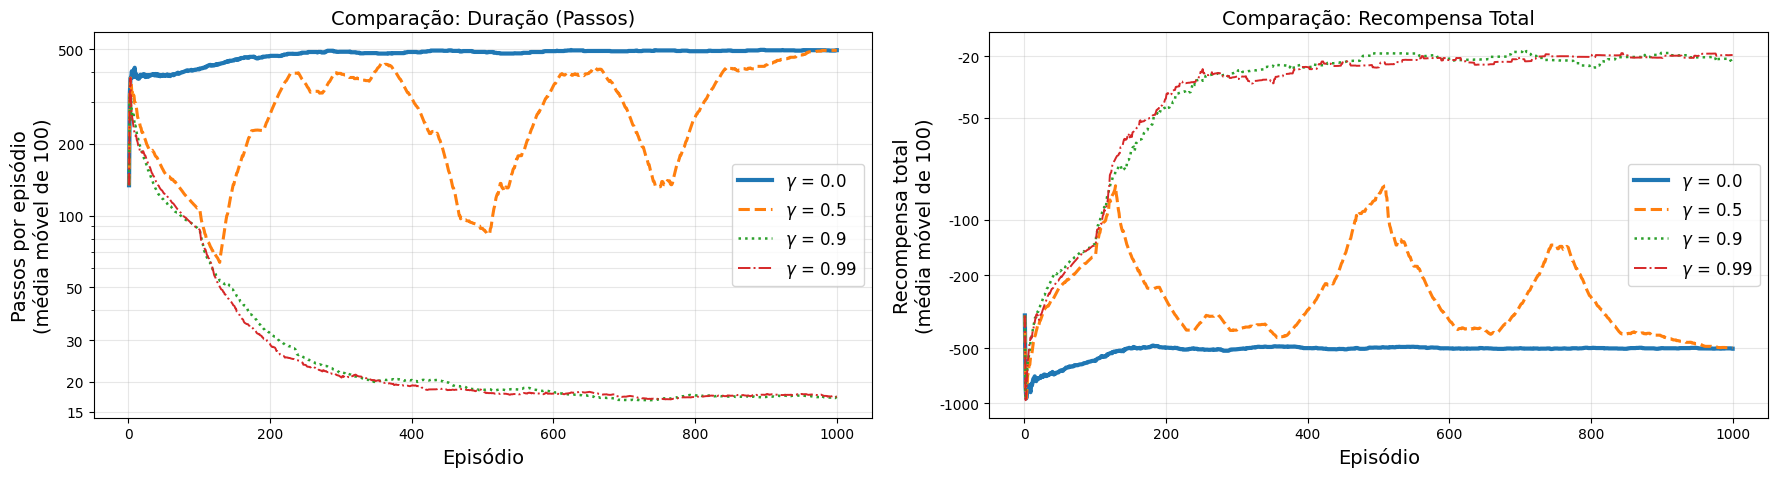

TABELA DE RESULTADOS (AVALIAÇÃO E TRAJETÓRIA GULOSA)


,Chegada ao Alvo (Aprendida),Rec. Total Média (Aprendida),Duração Média (Aprendida),Passos (Gulosa),Rec. Total (Gulosa)
gamma,,,,,
0.00,0.0,-500.99,500.00,200,-200.0
0.50,0.0,-500.99,500.00,200,-200.0
0.90,1.0,-21.33,17.37,15,-15.0
0.99,1.0,-23.19,17.25,15,-15.0


In [ ]:
gammas = [0.0, 0.5, 0.9, 0.99]
histories_gamma = {}
resultados_gamma = []

for gamma in gammas:
    print(f"Sarsa com gamma (γ) = {gamma}")

    # 1. Criação dos novos parâmetros a partir do baseline
    params_exp = params._replace(discount_factor=gamma)

    # 2. Instanciação de ambiente e agente para cada execução
    train_env = make_env()
    agent = SarsaAgent(params_exp, seed=SEED)

    # 3. Treinamento
    history = train_agent(agent, train_env, params_exp.n_episodes)
    histories_gamma[f"$\\gamma$ = {gamma}"] = history

    # 4. Avaliação da política aprendida
    eval_metrics = evaluate_policy(agent)

    # 5. Avaliação da trajetória gulosa
    states, actions, rewards = simulate_trajectory(agent, ENV_ID)
    passos_gulosos = len(actions)
    recompensa_gulosa = sum(rewards)

    # 6. Registro dos dados para a tabela
    resultados_gamma.append({
        "gamma": gamma,
        "Chegada ao Alvo (Aprendida)": eval_metrics["chegada ao alvo"],
        "Rec. Total Média (Aprendida)": eval_metrics["recompensa total média"],
        "Duração Média (Aprendida)": eval_metrics["duração média"],
        "Passos (Gulosa)": passos_gulosos,
        "Rec. Total (Gulosa)": recompensa_gulosa
    })

    # 7. Figura da trajetória gulosa para esta execução
    title = f"Trajetória gulosa ($\\gamma$ = {gamma}): {passos_gulosos} passos, recompensa total {recompensa_gulosa:.0f}"
    _ = plot_trajectory(ENV_ID, states, title=title)

# 8. Curvas de comparação (duração e recompensa total) sobrepostas
print("COMPARAÇÃO DAS CURVAS DE APRENDIZADO")
fig, axs = plt.subplots(1, 2, figsize=(18, 5))
plot_comparison(histories_gamma, metric="lengths", ax=axs[0])
axs[0].set_title("Comparação: Duração (Passos)")

plot_comparison(histories_gamma, metric="returns", ax=axs[1])
axs[1].set_title("Comparação: Recompensa Total")

plt.tight_layout()
plt.show()

# 9. Exibição da Tabela Final
print("TABELA DE RESULTADOS (AVALIAÇÃO E TRAJETÓRIA GULOSA)")
df_gamma = pd.DataFrame(resultados_gamma)
df_gamma.set_index("gamma", inplace=True)
display(df_gamma)

- **(a)**: Para $\gamma=0.0$ e $\gamma=0.5$, o agente foca no curto prazo e não consegue aprender a navegar para o alvo, esgotando o limite de passos e não atingindo o objetivo final em nenhuma execução. Isso acontece pois todos os passos seguros dão a mesma recompensa negativa -1, fazendo com que todas as ações pareçam igualmente ruins. Como todas as ações estão empatadas em -1 (no caso $\gamma=0.5$ o valor da recompensa do alvo é tão pequeno que não é suficiente para quebrar o empate), a função np.argmax(Q[obs]) escolhe sempre a ação de menor índice (que é ir para cima). Em contraste, para os valores $\gamma=0.9$ e $\gamma=0.99$, o agente valoriza as recompensas a longo prazo, aprendendo uma trajetória de 15 passos.

## 3. Efeito do parâmetro $\epsilon$

<div style="padding: 10px; border-left: 5px solid #27ae60; background-color: #f4fbf7; margin-bottom: 10px;">
  <b style="color: #27ae60;">🟢 O QUE DETALHAR NA TAREFA 3 (epsilon):</b>
  <ul style="color: #1e824c; margin-bottom: 0;">
    <li><b>Distância ao penhasco:</b> À medida que $\epsilon$ aumenta (bash.001 	o 0.3$), o SARSA afasta sua trajetória cada vez mais do penhasco para compensar o aumento da frequência de saltos aleatórios.</li>
    <li><b>Diferença entre gulosa e política aprendida:</b> Quanto maior o $\epsilon$, maior essa diferença, pois a política avaliada comete ações exploratórias em 30% dos passos para $\epsilon=0.3$, sofrendo quedas e penalidades.</li>
  </ul>
</div>
<div style="padding: 10px; border-left: 5px solid #c0392b; background-color: #fdf7f7;">
  <b style="color: #c0392b;">🔴 O QUE PODE GERAR DÚVIDA / PEGADINHA:</b>
  <p style="color: #962d22; margin: 5px 0 0 0;">Se $\epsilon=0.001$ explora quase nada, por que ele chega bem ao alvo? <b>Resposta:</b> Porque em 1000 episódios com 500 passos máximos, mesmo 0.1% de exploração somado à inicialização uniforme da política garante visitas suficientes para encontrar o penhasco e o alvo.</p>
</div>

**Experimento:** treine o Sarsa para $\epsilon \in \{10^{-3},\ 10^{-2},\ 10^{-1},\ 0.3\}$, com um ambiente e um agente novos para cada valor, fixando:

- $\alpha = 0.1$;
- $\gamma = 0.9$;
- `n_episodes = 1000`;
- os demais parâmetros do baseline.

**Perguntas:**

- **(a)** Como a distância entre a trajetória gulosa e o penhasco muda com $\epsilon$, e o que no Sarsa explica isso?
- **(b)** Como varia com $\epsilon$ a diferença entre a recompensa total média da política aprendida e a da trajetória gulosa? Por quê?

### Resposta

Sarsa com epsilon (ε) = 0.001


Treinando:   0%|          | 0/1000 [00:00<?, ?episódio/s]

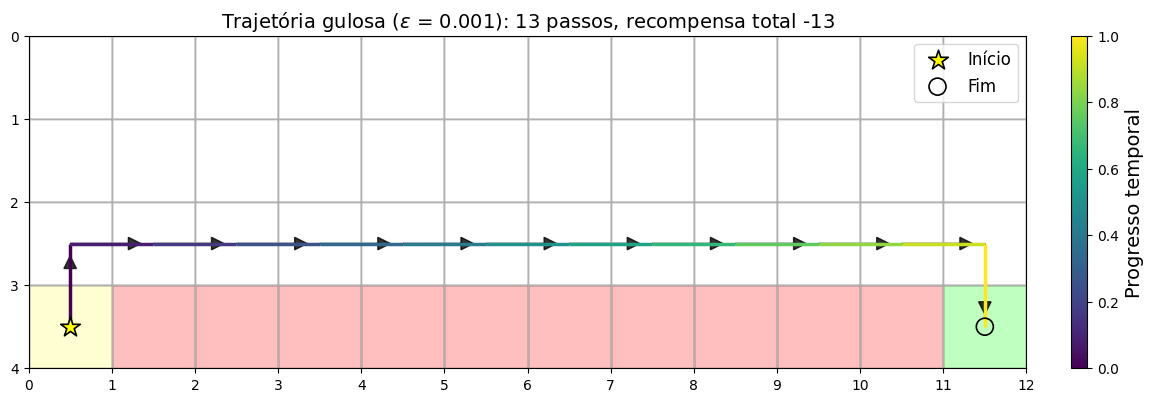

Sarsa com epsilon (ε) = 0.01


Treinando:   0%|          | 0/1000 [00:00<?, ?episódio/s]

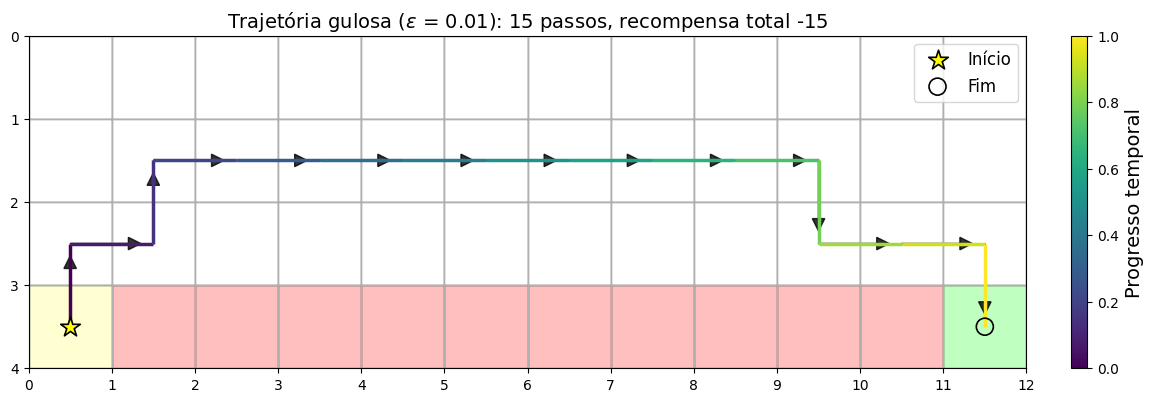

Sarsa com epsilon (ε) = 0.1


Treinando:   0%|          | 0/1000 [00:00<?, ?episódio/s]

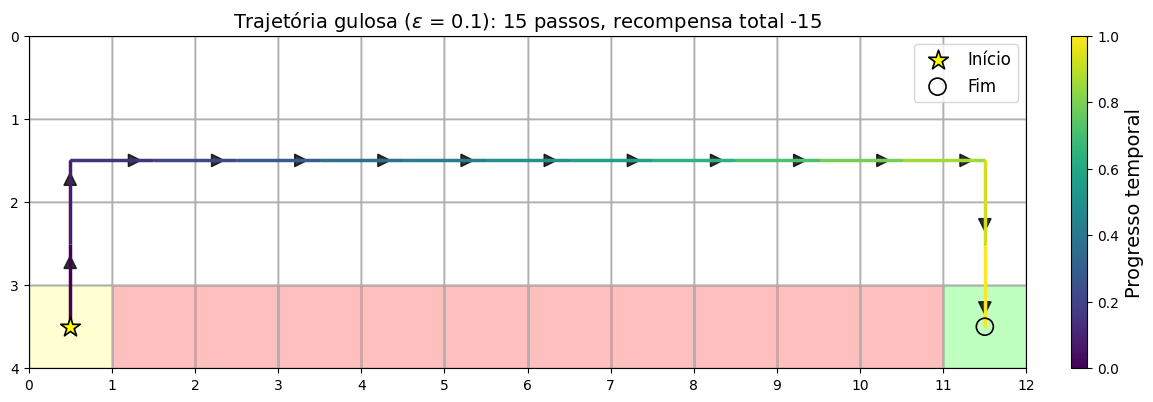

Sarsa com epsilon (ε) = 0.3


Treinando:   0%|          | 0/1000 [00:00<?, ?episódio/s]

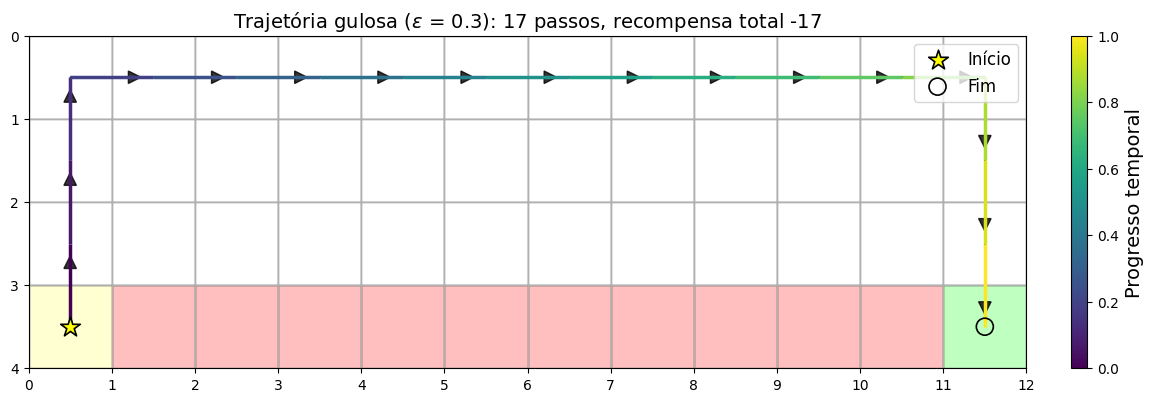

COMPARAÇÃO DAS CURVAS DE APRENDIZADO


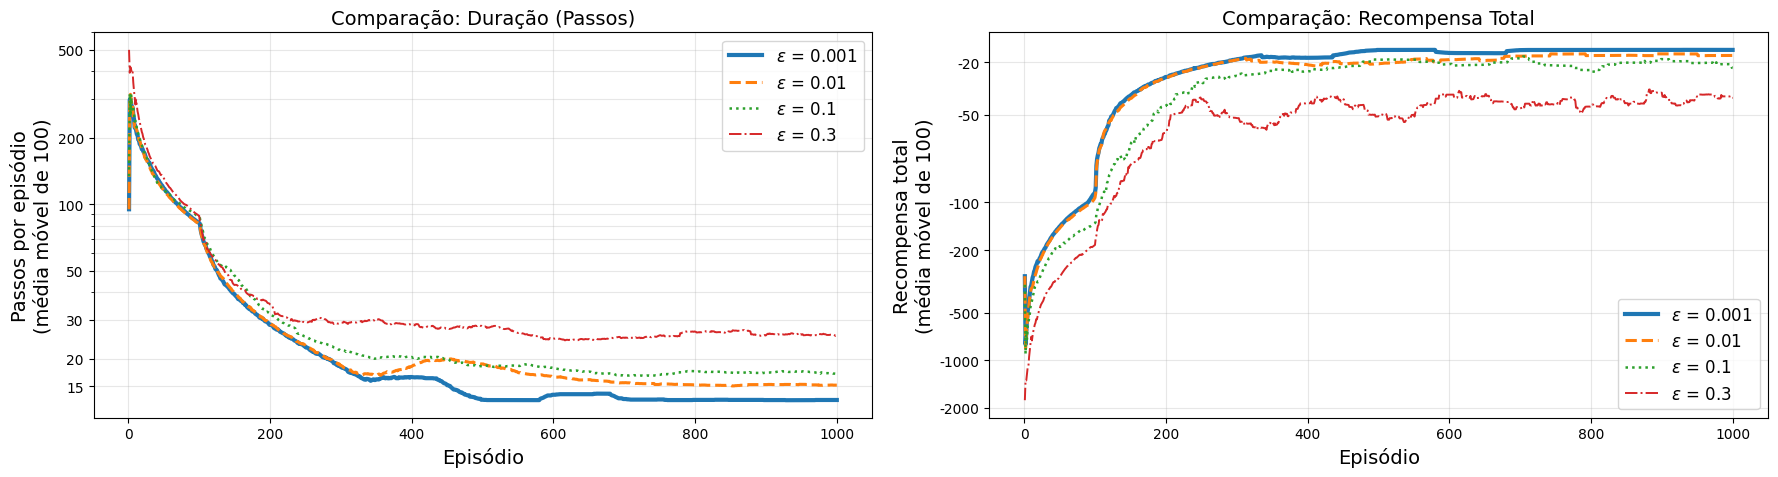

TABELA DE RESULTADOS (AVALIAÇÃO E TRAJETÓRIA GULOSA)


,Chegada ao Alvo (Aprendida),Rec. Total Média (Aprendida),Duração Média (Aprendida),Passos (Gulosa),Rec. Total (Gulosa)
epsilon,,,,,
0.001,1.0,-13.00,13.00,13,-13.0
0.010,1.0,-16.70,15.71,15,-15.0
0.100,1.0,-21.33,17.37,15,-15.0
0.300,1.0,-38.33,25.46,17,-17.0


In [ ]:
epsilons = [0.001, 0.01, 0.1, 0.3]
histories_eps = {}
resultados_eps = []

for eps in epsilons:
    print(f"Sarsa com epsilon (ε) = {eps}")

    # 1. Criação dos novos parâmetros a partir do baseline
    params_exp = params._replace(epsilon=eps)

    # 2. Instanciação de ambiente e agente para cada execução
    train_env = make_env()
    agent = SarsaAgent(params_exp, seed=SEED)

    # 3. Treinamento
    history = train_agent(agent, train_env, params_exp.n_episodes)
    histories_eps[f"$\\epsilon$ = {eps}"] = history

    # 4. Avaliação da política aprendida
    eval_metrics = evaluate_policy(agent)

    # 5. Avaliação da trajetória gulosa
    states, actions, rewards = simulate_trajectory(agent, ENV_ID)
    passos_gulosos = len(actions)
    recompensa_gulosa = sum(rewards)

    # 6. Registro dos dados para a tabela
    resultados_eps.append({
        "epsilon": eps,
        "Chegada ao Alvo (Aprendida)": eval_metrics["chegada ao alvo"],
        "Rec. Total Média (Aprendida)": eval_metrics["recompensa total média"],
        "Duração Média (Aprendida)": eval_metrics["duração média"],
        "Passos (Gulosa)": passos_gulosos,
        "Rec. Total (Gulosa)": recompensa_gulosa
    })

    # 7. Figura da trajetória gulosa para esta execução
    title = f"Trajetória gulosa ($\\epsilon$ = {eps}): {passos_gulosos} passos, recompensa total {recompensa_gulosa:.0f}"
    _ = plot_trajectory(ENV_ID, states, title=title)

# 8. Curvas de comparação (duração e recompensa total)
print("COMPARAÇÃO DAS CURVAS DE APRENDIZADO")
fig, axs = plt.subplots(1, 2, figsize=(18, 5))
plot_comparison(histories_eps, metric="lengths", ax=axs[0])
axs[0].set_title("Comparação: Duração (Passos)")

plot_comparison(histories_eps, metric="returns", ax=axs[1])
axs[1].set_title("Comparação: Recompensa Total")

plt.tight_layout()
plt.show()

# 9. Exibição da Tabela Final
print("TABELA DE RESULTADOS (AVALIAÇÃO E TRAJETÓRIA GULOSA)")
df_eps = pd.DataFrame(resultados_eps)
df_eps.set_index("epsilon", inplace=True)
display(df_eps)

- **(a)**: A distância entre a trajetória gulosa e o penhasco aumenta à medida que o $\epsilon$ aumenta. No Sarsa, se $\epsilon$ for alto, a política determina que o agente efetuará ações exploratórias frequentemente. Como a queda no penhasco penaliza a estimativa dos estados vizinhos, o Sarsa aprende que a margem do penhasco é insegura quando a exploração é frequente, compensando os saltos aleatórios com uma rota mais distante e segura.
- **(b)**: A diferença entre a recompensa total média da política aprendida e a recompensa total da trajetória gulosa aumenta à medida que $\epsilon$ aumenta. Esta diferença se deve ao fato de a trajetória gulosa apenas selecionar a ação ótima determinada por $\arg\max_a q(s,a)$, não efetuando exploração. A política aprendida, sendo $\epsilon$-gulosa, continua a explorar durante a avaliação, e quanto maior for o $\epsilon$, mais o agente se desviará da rota ótima para estados subótimos, penalizando a recompensa total e aumentando o número de passos.

## 4. Efeito do número de episódios ($N$)

<div style="padding: 10px; border-left: 5px solid #27ae60; background-color: #f4fbf7; margin-bottom: 10px;">
  <b style="color: #27ae60;">🟢 O QUE DETALHAR NA TAREFA 4 (N):</b>
  <ul style="color: #1e824c; margin-bottom: 0;">
    <li><b>Necessidade de N grande:</b> Apenas com =1000$ o agente chega ao alvo de forma consistente (100% de sucesso).</li>
    <li><b>Propagação 1-step lenta:</b> Como o SARSA atualiza apenas 1 passo por transição ( 	o s_{t+1}$), a informação de que o alvo está no canto direito precisa de centenas de episódios para retropropagar pelos 15 passos até o estado inicial.</li>
  </ul>
</div>
<div style="padding: 10px; border-left: 5px solid #c0392b; background-color: #fdf7f7;">
  <b style="color: #c0392b;">🔴 O QUE PODE GERAR DÚVIDA / PEGADINHA:</b>
  <p style="color: #962d22; margin: 5px 0 0 0;">Com =100$, por que a taxa de sucesso ainda é baixa se 100 episódios parece muito? <b>Resposta:</b> No CliffWalking, a maioria dos passos iniciais resulta em quedas no penhasco (-100) ou esgotamento de passos (500 passos). Até o agente encontrar o alvo por exploração e essa recompensa positiva retroceder até o início, são necessários centenas de episódios.</p>
</div>

**Experimento:** treine o Sarsa para `n_episodes` $\in \{1,\ 10,\ 100,\ 1000\}$, com um ambiente e um agente novos para cada valor, fixando:

- $\alpha = 0.1$;
- $\gamma = 0.9$;
- $\epsilon = 0.1$;
- os demais parâmetros do baseline.

**Perguntas:**

- **(a)** Para quais valores de $N$ a política aprendida leva o agente ao alvo de forma consistente? Explique esse comportamento.

### Resposta

Sarsa com N = 1 episódios


Treinando:   0%|          | 0/1 [00:00<?, ?episódio/s]

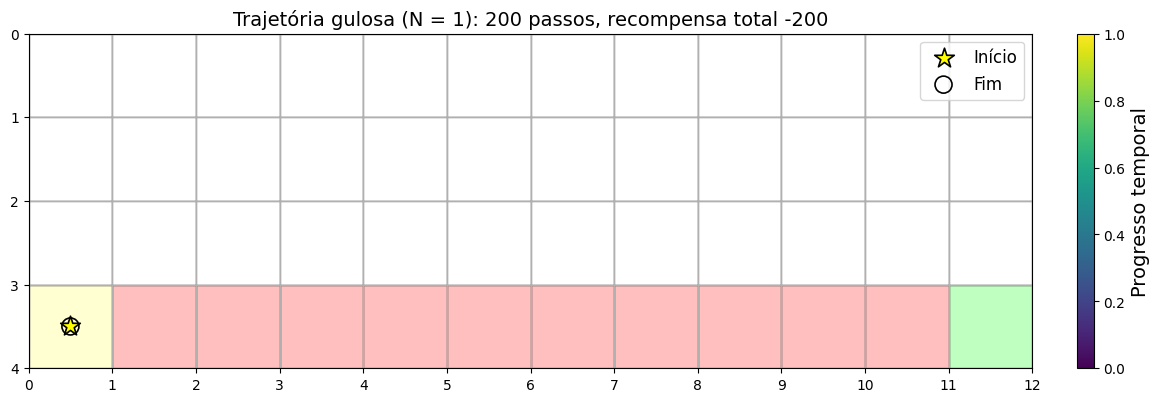

Sarsa com N = 10 episódios


Treinando:   0%|          | 0/10 [00:00<?, ?episódio/s]

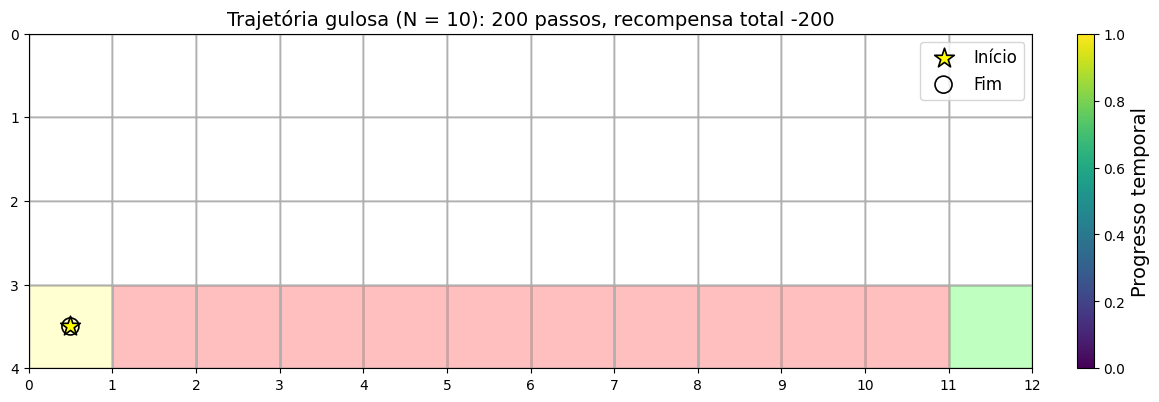

Sarsa com N = 100 episódios


Treinando:   0%|          | 0/100 [00:00<?, ?episódio/s]

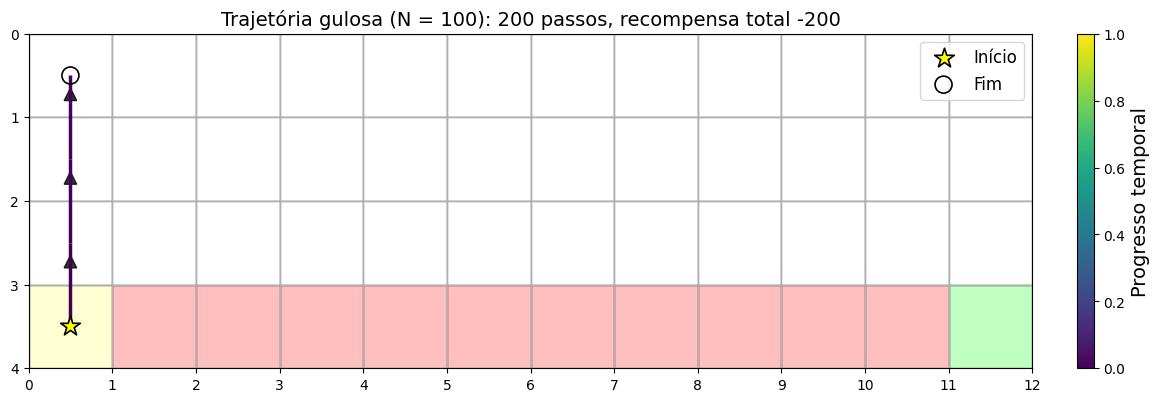

Sarsa com N = 1000 episódios


Treinando:   0%|          | 0/1000 [00:00<?, ?episódio/s]

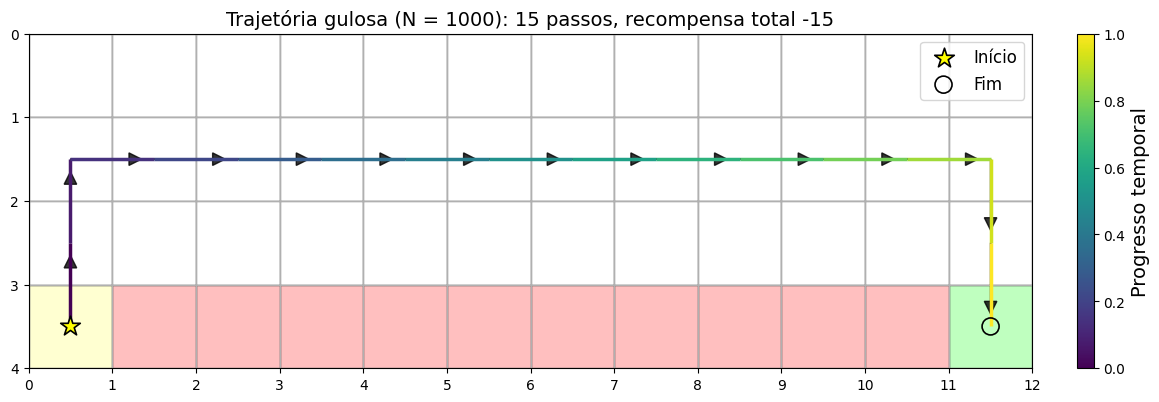

COMPARAÇÃO DAS CURVAS DE APRENDIZADO


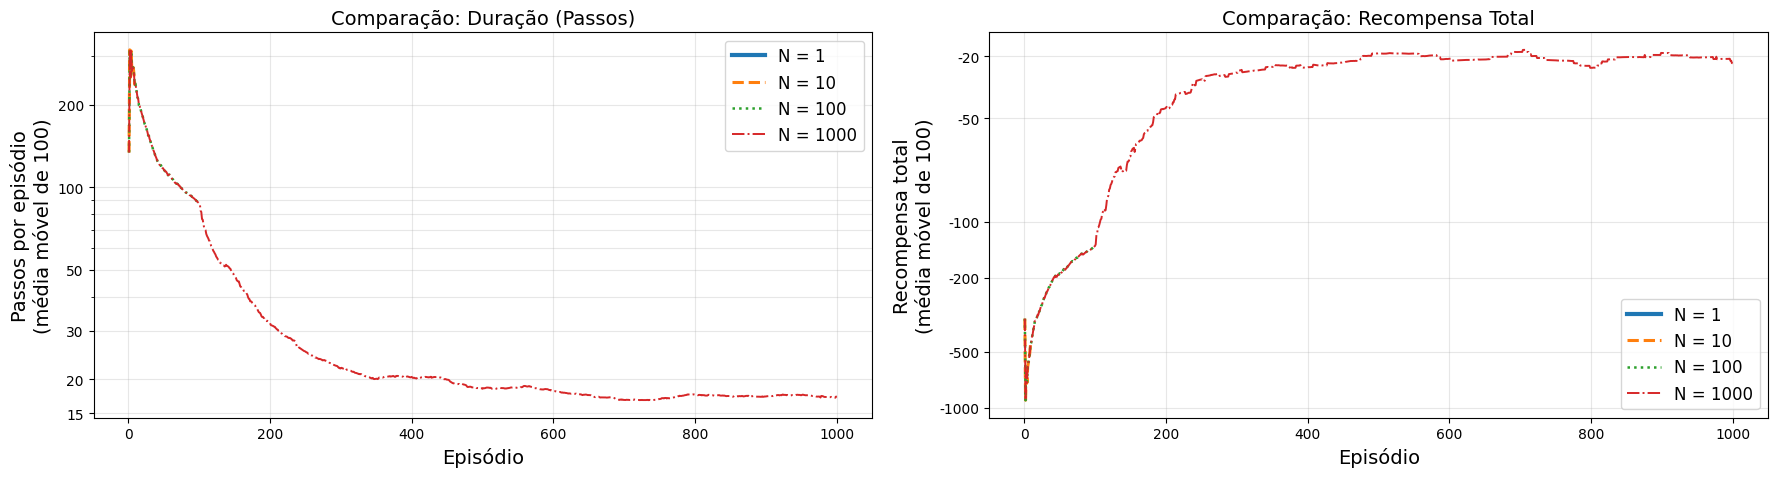

TABELA DE RESULTADOS (AVALIAÇÃO E TRAJETÓRIA GULOSA)


,Chegada ao Alvo (Aprendida),Rec. Total Média (Aprendida),Duração Média (Aprendida),Passos (Gulosa),Rec. Total (Gulosa)
N (Episódios),,,,,
1,0.00,-1715.72,500.00,200,-200.0
10,0.00,-985.10,500.00,200,-200.0
100,0.05,-537.54,489.03,200,-200.0
1000,1.00,-21.33,17.37,15,-15.0


In [ ]:
ns = [1, 10, 100, 1000]
histories_n = {}
resultados_n = []

for n in ns:
    print(f"Sarsa com N = {n} episódios")

    # 1. Criação dos novos parâmetros a partir do baseline
    params_exp = params._replace(n_episodes=n)

    # 2. Instanciação de ambiente e agente para cada execução
    train_env = make_env()
    agent = SarsaAgent(params_exp, seed=SEED)

    # 3. Treinamento
    history = train_agent(agent, train_env, params_exp.n_episodes)
    histories_n[f"N = {n}"] = history

    # 4. Avaliação da política aprendida (evaluate_policy)
    eval_metrics = evaluate_policy(agent)

    # 5. Avaliação da trajetória gulosa
    states, actions, rewards = simulate_trajectory(agent, ENV_ID)
    passos_gulosos = len(actions)
    recompensa_gulosa = sum(rewards)

    # 6. Registro dos dados para a tabela final
    resultados_n.append({
        "N (Episódios)": n,
        "Chegada ao Alvo (Aprendida)": eval_metrics["chegada ao alvo"],
        "Rec. Total Média (Aprendida)": eval_metrics["recompensa total média"],
        "Duração Média (Aprendida)": eval_metrics["duração média"],
        "Passos (Gulosa)": passos_gulosos,
        "Rec. Total (Gulosa)": recompensa_gulosa
    })

    # 7. Figura da trajetória gulosa para esta execução
    title = f"Trajetória gulosa (N = {n}): {passos_gulosos} passos, recompensa total {recompensa_gulosa:.0f}"
    _ = plot_trajectory(ENV_ID, states, title=title)

# 8. Curvas de comparação (duração e recompensa total)
print("COMPARAÇÃO DAS CURVAS DE APRENDIZADO")
fig, axs = plt.subplots(1, 2, figsize=(18, 5))
plot_comparison(histories_n, metric="lengths", ax=axs[0])
axs[0].set_title("Comparação: Duração (Passos)")

plot_comparison(histories_n, metric="returns", ax=axs[1])
axs[1].set_title("Comparação: Recompensa Total")

plt.tight_layout()
plt.show()

# 9. Exibição da Tabela Final
print("TABELA DE RESULTADOS (AVALIAÇÃO E TRAJETÓRIA GULOSA)")
df_n = pd.DataFrame(resultados_n)
df_n.set_index("N (Episódios)", inplace=True)
display(df_n)

- **(a)**: A política aprendida só leva o agente ao alvo de forma consistente com N = 1000. Este comportamento explica-se pela necessidade de exploração do espaço de estados no algoritmo Sarsa. Com um baixo número de episódios, o agente não tem tempo suficiente para visitar os pares estado-ação, testar diferentes trajetórias, cair no penhasco e propagar o conhecimento da recompensa final até ao estado inicial. A convergência para uma política robusta requer a repetição de vários episódios para que o agente deixe de errar por tentativa e consolide uma rota segura.